# Modelo de Predicción con Red Neuronal Artificial MLP - Adaptado para Cali

Este notebook implementa un modelo de **red neuronal artificial multicapa** mediante `MLPRegressor` para la predicción de **PM10** y **PM2.5**.

Aunque el archivo original tenía nombre asociado a GRU, el contenido del notebook trabaja con `MLPRegressor` de `scikit-learn`, lo cual evita depender de TensorFlow y permite ejecutarlo en Anaconda con mayor estabilidad.

## Ajustes incorporados

1. Carga robusta de archivos finales imputados.
2. Compatibilidad entre `PM2.5` y `PM25`.
3. Soporte para variables meteorológicas usadas en Cali:
   - `DViento`
   - `VViento`
   - `HAire2`
   - `HAire10`
   - `TAire2`
   - `TAire10`
   - `TMPR_AIR_10CM`
   - `P`
   - `RGlobal`
   - `PLiquida`
4. Detección automática de estaciones disponibles.
5. Construcción de base maestra por estación y fecha.
6. Construcción de variables temporales:
   - rezagos del contaminante;
   - medias móviles;
   - variables calendario;
   - covariables meteorológicas;
   - transformación circular de `DViento`.
7. Evaluación con particiones temporales y horizontes fijos.
8. Métricas de entrenamiento y prueba.
9. Tabla profesional de métricas.
10. Tabla de R² de entrenamiento vs R² de prueba.
11. Tabla de hiperparámetros usados.
12. Exportación de resultados.
13. Medición del tiempo total de ejecución.

## Nota para uso con Cali

Para usar este notebook con Cali, coloca en la misma carpeta del notebook los archivos finales imputados de Cali. El notebook buscará automáticamente nombres como:

```text
PM10_DATASET_FINAL_IMPUTADO.csv
PM25_DATASET_FINAL_IMPUTADO.csv
PM2.5_DATASET_FINAL_IMPUTADO.csv
RGlobal_dataset_completo_final_con_atipicos.csv
DViento_dataset_completo_final_con_atipicos.csv
VViento_dataset_completo_final_con_atipicos.csv
```

y otras variantes equivalentes.

### Diagnóstico adicional incorporado
Se incluye el análisis de **residuales temporales** definido como observado menos predicho, tanto para el mejor escenario mostrado en el notebook como para todos los escenarios guardados en archivos de salida.


### Control automático de alineación temporal (V2)
La versión V2 incorpora diagnóstico de **desfase temporal** entre la serie observada y la predicción. El notebook **no desplaza artificialmente** las predicciones después de observar la prueba. En su lugar, calcula el lag de máxima correlación, penaliza el desfase durante la selección por validación temporal y conserva para visualización el escenario con mejor equilibrio entre error, R² y alineación temporal.


### Actualización V3
- Se generan figuras de **entrenamiento + prueba real + predicción** para cada escenario 60/40, 70/30, 80/20, 90/10 y horizontes 7, 30 y 90 días.
- Debajo de cada figura se muestra el **residual temporal** `Real - Predicción` sobre el mismo eje de fechas.
- Se exportan tiempos **acumulados y detallados por intervalo/escenario**, además del tiempo total del notebook.


In [1]:
# ============================================================
# INICIO DE MEDICIÓN DEL TIEMPO TOTAL DEL NOTEBOOK
# ============================================================

import time
from datetime import datetime

TIEMPO_INICIO_NOTEBOOK = time.perf_counter()
FECHA_HORA_INICIO_NOTEBOOK = datetime.now()

print("Inicio de ejecución del notebook:")
print(FECHA_HORA_INICIO_NOTEBOOK.strftime("%Y-%m-%d %H:%M:%S"))

Inicio de ejecución del notebook:
2026-08-20 23:15:53


In [2]:
# ============================================================
# IMPORTACIÓN DE LIBRERÍAS
# ============================================================

import os
import re
import gc
import warnings
from pathlib import Path
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)
plt.rcParams["figure.figsize"] = (13, 5)

SEED = 42
np.random.seed(SEED)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [3]:

# ============================================================
# CONFIGURACIÓN DE CARGA Y EXPLORACIÓN
# ============================================================

CIUDAD_ANALISIS = "CALI"
TARGETS_A_EVALUAR = ["PM10", "PM25"]
COVARIABLES_CANDIDATAS = [
    "DViento", "VViento", "HAire2", "HAire10", "TAire2", "TAire10",
    "TMPR_AIR_10CM", "P", "RGlobal", "PLiquida", "RUVb"
]

# Se prioriza integrar los archivos de Cali para evitar tomar por accidente
# una base maestra antigua correspondiente a otra ciudad.
USAR_BASE_MAESTRA_SI_EXISTE = False

OUT_DIR = f"EDA_MLP_{CIUDAD_ANALISIS}"
TABLAS_DIR = Path(OUT_DIR) / "tablas"
GRAFICAS_DIR = Path(OUT_DIR) / "graficas"
MODELOS_DIR = Path(OUT_DIR) / "modelos"
for carpeta in [TABLAS_DIR, GRAFICAS_DIR, MODELOS_DIR]:
    carpeta.mkdir(parents=True, exist_ok=True)

display(Markdown("## Configuración de carga/EDA"))
display(pd.DataFrame([{
    "Ciudad": CIUDAD_ANALISIS,
    "Targets": str(TARGETS_A_EVALUAR),
    "Covariables_candidatas": str(COVARIABLES_CANDIDATAS),
    "Usar_base_maestra_si_existe": USAR_BASE_MAESTRA_SI_EXISTE
}]))


## Configuración de carga/EDA

,Ciudad,Targets,Covariables_candidatas,Usar_base_maestra_si_existe
0,CALI,"['PM10', 'PM25']","['DViento', 'VViento', 'HAire2', 'HAire10', 'T...",False


In [4]:
# ============================================================
# RUTAS DE TRABAJO Y BÚSQUEDA ROBUSTA DE ARCHIVOS
# ============================================================

BASE_DIR = Path(".")

PATRONES_BASE_MAESTRA = [
    f"base_maestra_calidad_aire_modelado_{CIUDAD_ANALISIS}.csv",
    "base_maestra_calidad_aire_modelado.csv",
    "base_maestra_calidad_aire_modelado_GRU.csv",
    "base_maestra_calidad_aire_modelado_MLP.csv",
    "*base*maestra*calidad*aire*modelado*.csv",
    "*base*maestra*.csv",
]

def buscar_archivo(patrones):
    encontrados = []
    for patron in patrones:
        ruta = BASE_DIR / patron
        if ruta.exists():
            encontrados.append(ruta)
        encontrados.extend(sorted(BASE_DIR.glob(patron)))

    unicos = []
    vistos = set()
    for ruta in encontrados:
        ruta_txt = str(ruta)
        if ruta_txt not in vistos:
            unicos.append(ruta)
            vistos.add(ruta_txt)

    if unicos:
        return str(unicos[0])
    return None

PATH_BASE_MAESTRA = buscar_archivo(PATRONES_BASE_MAESTRA)

PATRONES_PATHS = {
    "PM10": [
        "PM10_DATASET_FINAL_IMPUTADO.csv",
        "PM10_dataset_completo_final_con_atipicos.csv",
        "PM10_dataset_completo_final_imputado_RF_atipicos*.csv",
        "PM10_dataset_final_imputado_RF_atipicos*.csv",
        "PM10_dataset_completo_final*.csv",
        "PM10_dataset_completo*.csv",
        "*PM10*DATASET*FINAL*IMPUTADO*.csv",
        "*PM10*final*atipicos*.csv",
        "*PM10*.csv",
        "*PM10*.xlsx",
        "*PM10*.xls",
    ],
    "PM25": [
        "PM25_DATASET_FINAL_IMPUTADO.csv",
        "PM2.5_DATASET_FINAL_IMPUTADO.csv",
        "PM25_dataset_completo_final_con_atipicos.csv",
        "PM2.5_dataset_completo_final_con_atipicos.csv",
        "PM25_dataset_completo_final_imputado_RF_atipicos*.csv",
        "PM2.5_dataset_completo_final_imputado_RF_atipicos*.csv",
        "PM25_dataset_final_imputado_RF_atipicos*.csv",
        "PM2.5_dataset_final_imputado_RF_atipicos*.csv",
        "PM25_dataset_completo_final*.csv",
        "PM2.5_dataset_completo_final*.csv",
        "PM25_dataset_completo*.csv",
        "PM2.5_dataset_completo*.csv",
        "*PM25*DATASET*FINAL*IMPUTADO*.csv",
        "*PM2.5*DATASET*FINAL*IMPUTADO*.csv",
        "*PM25*final*atipicos*.csv",
        "*PM2.5*final*atipicos*.csv",
        "*PM25*.csv",
        "*PM2.5*.csv",
        "*PM25*.xlsx",
        "*PM2.5*.xlsx",
    ],
    "DViento": [
        "DViento_DATASET_FINAL_IMPUTADO.csv",
        "DViento_dataset_completo_final_con_atipicos.csv",
        "DViento_dataset_completo_final*.csv",
        "DViento_dataset_final_imputado*.csv",
        "DViento.csv",
        "*DViento*DATASET*FINAL*IMPUTADO*.csv",
        "*DViento*final*atipicos*.csv",
        "*DViento*.csv",
        "*DViento*.xlsx",
        "*DViento*.xls",
    ],
    "VViento": [
        "VViento_DATASET_FINAL_IMPUTADO.csv",
        "VViento_dataset_completo_final_con_atipicos.csv",
        "VViento_dataset_completo_final*.csv",
        "VViento_dataset_final_imputado*.csv",
        "VViento.csv",
        "*VViento*DATASET*FINAL*IMPUTADO*.csv",
        "*VViento*final*atipicos*.csv",
        "*VViento*.csv",
        "*VViento*.xlsx",
        "*VViento*.xls",
    ],
    "HAire2": [
        "HAire2_DATASET_FINAL_IMPUTADO.csv",
        "HAire2_dataset_completo_final_con_atipicos.csv",
        "HAire2_dataset_completo_final*.csv",
        "HAire2.csv",
        "*HAire2*DATASET*FINAL*IMPUTADO*.csv",
        "*HAire2*final*atipicos*.csv",
        "*HAire2*.csv",
        "*HAire2*.xlsx",
        "*HAire2*.xls",
    ],
    "HAire10": [
        "HAire10_DATASET_FINAL_IMPUTADO.csv",
        "HAire10_dataset_completo_final_con_atipicos.csv",
        "HAire10_dataset_completo_final*.csv",
        "HAire10.csv",
        "*HAire10*DATASET*FINAL*IMPUTADO*.csv",
        "*HAire10*final*atipicos*.csv",
        "*HAire10*.csv",
        "*HAire10*.xlsx",
        "*HAire10*.xls",
    ],
    "TAire2": [
        "TAire2_DATASET_FINAL_IMPUTADO.csv",
        "TAire2_dataset_completo_final_con_atipicos.csv",
        "TAire2_dataset_completo_final*.csv",
        "TAire2.csv",
        "*TAire2*DATASET*FINAL*IMPUTADO*.csv",
        "*TAire2*final*atipicos*.csv",
        "*TAire2*.csv",
        "*TAire2*.xlsx",
        "*TAire2*.xls",
    ],
    "TAire10": [
        "TAire10_DATASET_FINAL_IMPUTADO.csv",
        "TAire10_dataset_completo_final_con_atipicos.csv",
        "TAire10_dataset_completo_final*.csv",
        "TAire10.csv",
        "*TAire10*DATASET*FINAL*IMPUTADO*.csv",
        "*TAire10*final*atipicos*.csv",
        "*TAire10*.csv",
        "*TAire10*.xlsx",
        "*TAire10*.xls",
    ],
    "TMPR_AIR_10CM": [
        "TMPR_AIR_10CM_DATASET_FINAL_IMPUTADO.csv",
        "TMPR_AIR_10CM_dataset_completo_final_con_atipicos.csv",
        "TMPR_AIR_10CM_dataset_completo_final*.csv",
        "TMPR AIR 10CM.csv",
        "TMPR_AIR_10CM.csv",
        "*TMPR*DATASET*FINAL*IMPUTADO*.csv",
        "*TMPR*final*atipicos*.csv",
        "*TMPR*.csv",
        "*TMPR*.xlsx",
        "*TMPR*.xls",
    ],
    "P": [
        "P_DATASET_FINAL_IMPUTADO.csv",
        "P_dataset_completo_final_con_atipicos.csv",
        "P_dataset_completo_final*.csv",
        "P.csv",
        "*P*DATASET*FINAL*IMPUTADO*.csv",
        "*P*final*atipicos*.csv",
        "P*.csv",
        "P*.xlsx",
        "P*.xls",
    ],
    "RGlobal": [
        "RGlobal_DATASET_FINAL_IMPUTADO.csv",
        "RGlobal_dataset_completo_final_con_atipicos.csv",
        "RGlobal_dataset_completo_final*.csv",
        "RGlobal.csv",
        "*RGlobal*DATASET*FINAL*IMPUTADO*.csv",
        "*RGlobal*final*atipicos*.csv",
        "*RGlobal*.csv",
        "*RGlobal*.xlsx",
        "*RGlobal*.xls",
    ],
    "PLiquida": [
        "PLiquida_DATASET_FINAL_IMPUTADO.csv",
        "PLiquida_dataset_completo_final_con_atipicos.csv",
        "PLiquida_dataset_completo_final*.csv",
        "PLiquida.csv",
        "*PLiquida*DATASET*FINAL*IMPUTADO*.csv",
        "*PLiquida*final*atipicos*.csv",
        "*PLiquida*.csv",
        "*PLiquida*.xlsx",
        "*PLiquida*.xls",
    ],
}

PATHS = {nombre: buscar_archivo(patrones) for nombre, patrones in PATRONES_PATHS.items()}

print("Base maestra detectada:", PATH_BASE_MAESTRA)
print("Usar base maestra existente:", USAR_BASE_MAESTRA_SI_EXISTE)

print("\nArchivos detectados por variable:")
for nombre, ruta in PATHS.items():
    print(nombre, "->", ruta, "| Existe:", bool(ruta and Path(ruta).exists()))

Base maestra detectada: base_maestra_calidad_aire_modelado_MLP_CALI.csv
Usar base maestra existente: False

Archivos detectados por variable:
PM10 -> PM10_dataset_completo_final.csv | Existe: True
PM25 -> PM25_dataset_completo_final.csv | Existe: True
DViento -> DViento_dataset_completo_final.csv | Existe: True
VViento -> VViento_dataset_completo_final.csv | Existe: True
HAire2 -> None | Existe: False
HAire10 -> HAire10_dataset_completo_final.csv | Existe: True
TAire2 -> None | Existe: False
TAire10 -> None | Existe: False
TMPR_AIR_10CM -> TMPR AIR 10CM_dataset_completo_final.csv | Existe: True
P -> P_dataset_completo_final.csv | Existe: True
RGlobal -> RGlobal_dataset_completo_final.csv | Existe: True
PLiquida -> None | Existe: False


In [5]:
# ============================================================
# FUNCIONES AUXILIARES ROBUSTAS PARA CARGA E INTEGRACIÓN
# ============================================================

def limpiar_nombre_columna(col):
    col = str(col).replace("\ufeff", "").strip()
    col = re.sub(r"\s+", " ", col)
    return col

def normalizar_texto_columna(txt):
    txt = limpiar_nombre_columna(txt).lower()
    reemplazos = {"á": "a", "é": "e", "í": "i", "ó": "o", "ú": "u", "ñ": "n"}
    for a, b in reemplazos.items():
        txt = txt.replace(a, b)
    for ch in [".", "_", "-", " ", "/", "\\", "(", ")", "[", "]"]:
        txt = txt.replace(ch, "")
    return txt

def load_table(path, sheet_preferida=None):
    if path is None:
        raise FileNotFoundError("La ruta recibida es None. No se detectó archivo para esta variable.")

    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"No se encontró el archivo: {path}\n"
            "Verifica que el archivo esté en la misma carpeta del notebook o ajusta PATHS."
        )

    def limpiar_columnas(df):
        df = df.copy()
        df.columns = [limpiar_nombre_columna(c) for c in df.columns]
        return df

    suffix = path.suffix.lower()

    if suffix == ".csv":
        try:
            return limpiar_columnas(pd.read_csv(path, encoding="utf-8"))
        except UnicodeDecodeError:
            return limpiar_columnas(pd.read_csv(path, encoding="latin1"))

    if suffix in [".xlsx", ".xls"]:
        try:
            excel = pd.ExcelFile(path)
            hojas = excel.sheet_names

            posibles_hojas = [
                sheet_preferida,
                "DATASET_FINAL",
                "dataset_final",
                "PM10_final",
                "PM25_final",
                "PM2.5_final",
                "VViento_final",
                "detalle_completo",
            ]

            hoja = None
            for h in posibles_hojas:
                if h in hojas:
                    hoja = h
                    break
            if hoja is None:
                hoja = hojas[0]

            return limpiar_columnas(pd.read_excel(path, sheet_name=hoja))

        except Exception:
            try:
                return limpiar_columnas(pd.read_csv(path, encoding="utf-8"))
            except UnicodeDecodeError:
                return limpiar_columnas(pd.read_csv(path, encoding="latin1"))
            except Exception as e_csv:
                raise ValueError(
                    f"No se pudo leer el archivo {path} ni como Excel ni como CSV. Error final: {e_csv}"
                )

    try:
        return limpiar_columnas(pd.read_csv(path, encoding="utf-8"))
    except UnicodeDecodeError:
        return limpiar_columnas(pd.read_csv(path, encoding="latin1"))

def encontrar_columna(df, alias):
    columnas_norm = {normalizar_texto_columna(c): c for c in df.columns}

    for a in alias:
        a_norm = normalizar_texto_columna(a)
        if a_norm in columnas_norm:
            return columnas_norm[a_norm]

    for c in df.columns:
        c_norm = normalizar_texto_columna(c)
        for a in alias:
            a_norm = normalizar_texto_columna(a)
            if a_norm == c_norm:
                return c

    return None

def alias_variable_base(value_col):
    alias = [value_col]

    alias_map = {
        "PM10": ["PM10", "PM 10", "PM_10", "PM10_final", "PM10_RF_final", "PM10_limpio_sin_atipicos"],
        "PM25": ["PM25", "PM2.5", "PM 2.5", "PM_2_5", "PM2_5", "PM2.5_final", "PM25_final", "PM2.5_RF_final", "PM25_RF_final", "PM2.5_limpio_sin_atipicos", "PM25_limpio_sin_atipicos"],
        "PM2.5": ["PM25", "PM2.5", "PM 2.5", "PM_2_5", "PM2_5", "PM2.5_final", "PM25_final", "PM2.5_RF_final", "PM25_RF_final", "PM2.5_limpio_sin_atipicos", "PM25_limpio_sin_atipicos"],
        "DViento": ["DViento", "Direccion viento", "Dirección viento", "Direccion del viento", "Dirección del viento", "wind direction"],
        "VViento": ["VViento", "Velocidad viento", "Velocidad del viento", "wind speed"],
        "HAire2": ["HAire2", "H Aire 2", "Humedad Aire 2", "Humedad relativa 2m", "Humedad relativa"],
        "HAire10": ["HAire10", "H Aire 10", "Humedad Aire 10", "Humedad relativa 10m"],
        "TAire2": ["TAire2", "T Aire 2", "Temperatura Aire 2", "Temperatura 2m"],
        "TAire10": ["TAire10", "T Aire 10", "Temperatura Aire 10", "Temperatura 10m"],
        "TMPR_AIR_10CM": ["TMPR_AIR_10CM", "TMPR AIR 10CM", "TMPR_AIR_10CM_final", "Temperatura aire 10cm", "TMPR"],
        "P": ["P", "Presion", "Presión", "Presion atmosferica", "Presión atmosférica"],
        "RGlobal": ["RGlobal", "Radiacion global", "Radiación global", "Rad Global"],
        "PLiquida": ["PLiquida", "P Liquida", "Precipitacion liquida", "Precipitación líquida", "Lluvia"],
    }

    alias += alias_map.get(value_col, [])
    return alias

def standardize_base(df, value_col, rename=None):
    df = df.copy()
    df.columns = [limpiar_nombre_columna(c) for c in df.columns]

    col_est = encontrar_columna(
        df,
        ["Estacion", "Estación", "Nombre de estación", "Nombre estacion", "station", "site", "punto"]
    )
    col_fecha = encontrar_columna(
        df,
        ["Fecha inicial", "Fecha", "fecha", "date", "Date", "Fecha Inicial"]
    )

    alias_variable = alias_variable_base(value_col)
    col_var = encontrar_columna(df, alias_variable)

    if col_est is None:
        raise ValueError(f"No se encontró columna de estación. Columnas disponibles: {df.columns.tolist()}")

    if col_fecha is None:
        raise ValueError(f"No se encontró columna de fecha. Columnas disponibles: {df.columns.tolist()}")

    if col_var is None:
        raise ValueError(
            f"No se encontró la columna para la variable {value_col}. "
            f"Alias buscados: {alias_variable}. "
            f"Columnas disponibles: {df.columns.tolist()}"
        )

    final_col = rename if rename else value_col

    out = df[[col_est, col_fecha, col_var]].copy()
    out = out.rename(columns={
        col_est: "Estacion",
        col_fecha: "Fecha inicial",
        col_var: final_col
    })

    out["Estacion"] = out["Estacion"].astype(str).str.strip().str.upper()
    out["Fecha inicial"] = pd.to_datetime(out["Fecha inicial"], errors="coerce")
    out[final_col] = pd.to_numeric(out[final_col], errors="coerce")

    out = out.dropna(subset=["Estacion", "Fecha inicial"])
    out = (
        out.groupby(["Estacion", "Fecha inicial"], as_index=False)[final_col]
        .mean()
        .sort_values(["Estacion", "Fecha inicial"])
        .reset_index(drop=True)
    )

    return out

def preparar_base_maestra_directa(df):
    df = df.copy()
    df.columns = [limpiar_nombre_columna(c) for c in df.columns]

    col_est = encontrar_columna(df, ["Estacion", "Estación", "Nombre estacion", "Nombre de estación"])
    col_fecha = encontrar_columna(df, ["Fecha inicial", "Fecha", "fecha", "date"])

    if col_est is None or col_fecha is None:
        raise ValueError("La base maestra debe tener columnas de estación y fecha.")

    df = df.rename(columns={col_est: "Estacion", col_fecha: "Fecha inicial"})

    renombres = {}
    for destino in ["PM10", "PM25", "DViento", "VViento", "HAire2", "HAire10", "TAire2", "TAire10", "TMPR_AIR_10CM", "P", "RGlobal", "PLiquida"]:
        col = encontrar_columna(df, alias_variable_base(destino))
        if col is not None and col not in ["Estacion", "Fecha inicial"]:
            renombres[col] = destino

    df = df.rename(columns=renombres)

    df["Estacion"] = df["Estacion"].astype(str).str.strip().str.upper()
    df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")

    for col in df.columns:
        if col not in ["Estacion", "Fecha inicial", "Fecha final"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(subset=["Estacion", "Fecha inicial"])
    df = df.sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

    return df

In [6]:
# ============================================================
# CARGA E INTEGRACIÓN ROBUSTA DE BASES
# ============================================================

if USAR_BASE_MAESTRA_SI_EXISTE and PATH_BASE_MAESTRA is not None:
    print("Cargando base maestra existente:")
    print(PATH_BASE_MAESTRA)
    df_master = preparar_base_maestra_directa(load_table(PATH_BASE_MAESTRA))
else:
    print("No se usó base maestra existente. Se integrarán las variables desde archivos individuales.")

    bases = []
    variables_integradas = []
    errores_carga = []

    for variable, ruta in PATHS.items():
        if ruta is None:
            continue

        try:
            df_variable = load_table(ruta)
            rename = "PM25" if variable in ["PM25", "PM2.5"] else variable
            base_var = standardize_base(df_variable, variable, rename=rename)
            bases.append(base_var)
            variables_integradas.append({
                "Variable": rename,
                "Archivo": ruta,
                "Registros": len(base_var),
                "Estaciones": base_var["Estacion"].nunique(),
                "Fecha_minima": base_var["Fecha inicial"].min(),
                "Fecha_maxima": base_var["Fecha inicial"].max(),
            })
            print(f"OK - {rename}: {ruta}")
        except Exception as e:
            errores_carga.append({
                "Variable": variable,
                "Archivo": ruta,
                "Error": str(e)
            })
            print(f"No se pudo cargar {variable}: {e}")

    if not bases:
        raise FileNotFoundError(
            "No se pudo integrar ninguna variable. "
            "Verifica que los archivos finales imputados estén en la misma carpeta del notebook."
        )

    df_master = reduce(
        lambda left, right: pd.merge(left, right, on=["Estacion", "Fecha inicial"], how="outer"),
        bases
    )
    df_master = df_master.sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

    variables_integradas_df = pd.DataFrame(variables_integradas)
    errores_carga_df = pd.DataFrame(errores_carga)

    display(Markdown("## Variables integradas correctamente"))
    display(variables_integradas_df)

    if not errores_carga_df.empty:
        display(Markdown("## Variables no integradas o con errores de carga"))
        display(errores_carga_df)

    variables_integradas_df.to_csv(TABLAS_DIR / "variables_integradas_base_maestra_MLP.csv", index=False, encoding="utf-8-sig")
    errores_carga_df.to_csv(TABLAS_DIR / "errores_carga_variables_MLP.csv", index=False, encoding="utf-8-sig")

# Validación mínima de targets.
targets_en_base = [t for t in TARGETS_A_EVALUAR if t in df_master.columns]
if not targets_en_base:
    raise ValueError(
        "La base integrada no contiene PM10 ni PM25/PM2.5. "
        f"Columnas disponibles: {df_master.columns.tolist()}"
    )

print("Dimensión de la base integrada:", df_master.shape)
display(df_master.head())
display(df_master.tail())

ruta_salida_master = Path(OUT_DIR) / f"base_maestra_calidad_aire_modelado_MLP_{CIUDAD_ANALISIS}.csv"
df_master.to_csv(ruta_salida_master, index=False, encoding="utf-8-sig")
df_master.to_csv(f"base_maestra_calidad_aire_modelado_MLP_{CIUDAD_ANALISIS}.csv", index=False, encoding="utf-8-sig")

resumen_base = pd.DataFrame([{
    "Ciudad_analisis": CIUDAD_ANALISIS,
    "Registros": len(df_master),
    "Estaciones": df_master["Estacion"].nunique(),
    "Fecha_minima": df_master["Fecha inicial"].min(),
    "Fecha_maxima": df_master["Fecha inicial"].max(),
    "Columnas": ", ".join(df_master.columns.astype(str))
}])

display(Markdown("## Resumen de la base maestra"))
display(resumen_base)

display(Markdown("## Estaciones detectadas"))
display(pd.DataFrame({"Estacion": sorted(df_master["Estacion"].dropna().unique())}))

No se usó base maestra existente. Se integrarán las variables desde archivos individuales.
OK - PM10: PM10_dataset_completo_final.csv
OK - PM25: PM25_dataset_completo_final.csv
OK - DViento: DViento_dataset_completo_final.csv
OK - VViento: VViento_dataset_completo_final.csv
OK - HAire10: HAire10_dataset_completo_final.csv
OK - TMPR_AIR_10CM: TMPR AIR 10CM_dataset_completo_final.csv
OK - P: P_dataset_completo_final.csv
OK - RGlobal: RGlobal_dataset_completo_final.csv


## Variables integradas correctamente

,Variable,Archivo,Registros,Estaciones,Fecha_minima,Fecha_maxima
0,PM10,PM10_dataset_completo_final.csv,365,1,2022-01-01,2022-12-31
1,PM25,PM25_dataset_completo_final.csv,365,1,2022-01-01,2022-12-31
2,DViento,DViento_dataset_completo_final.csv,365,1,2022-01-01,2022-12-31
3,VViento,VViento_dataset_completo_final.csv,365,1,2022-01-01,2022-12-31
4,HAire10,HAire10_dataset_completo_final.csv,365,1,2022-01-01,2022-12-31
5,TMPR_AIR_10CM,TMPR AIR 10CM_dataset_completo_final.csv,365,1,2022-01-01,2022-12-31
6,P,P_dataset_completo_final.csv,365,1,2022-01-01,2022-12-31
7,RGlobal,RGlobal_dataset_completo_final.csv,365,1,2022-01-01,2022-12-31


Dimensión de la base integrada: (365, 10)


,Estacion,Fecha inicial,PM10,PM25,DViento,VViento,HAire10,TMPR_AIR_10CM,P,RGlobal
0,PALMIRA,2022-01-01,28.779167,12.520833,132.583333,1.245833,84.366667,22.791667,674.733333,81.258333
1,PALMIRA,2022-01-02,26.645833,6.350000,136.625000,1.300000,74.720833,24.291667,675.304167,126.820833
2,PALMIRA,2022-01-03,28.575000,7.825000,143.083333,0.933333,86.337500,22.570833,675.820833,98.195833
3,PALMIRA,2022-01-04,31.741667,7.645833,206.166667,1.316667,77.820833,23.500000,674.791667,128.458333
4,PALMIRA,2022-01-05,31.750000,8.879167,210.291667,1.287500,79.095833,23.308333,673.908333,106.945833


,Estacion,Fecha inicial,PM10,PM25,DViento,VViento,HAire10,TMPR_AIR_10CM,P,RGlobal
360,PALMIRA,2022-12-27,26.400000,8.850000,167.791667,1.283333,78.766667,23.012500,676.062500,123.587500
361,PALMIRA,2022-12-28,27.007304,9.500840,76.166667,1.271581,84.050000,22.041667,676.081551,50.545833
362,PALMIRA,2022-12-29,26.360911,9.348014,137.279314,1.267957,79.933778,22.609474,675.477465,101.501868
363,PALMIRA,2022-12-30,31.697121,10.929576,133.208333,1.104167,63.315385,26.523077,675.600116,88.341667
364,PALMIRA,2022-12-31,25.283333,9.350000,140.125000,1.216667,88.258333,21.308333,676.395833,78.108333


## Resumen de la base maestra

,Ciudad_analisis,Registros,Estaciones,Fecha_minima,Fecha_maxima,Columnas
0,CALI,365,1,2022-01-01,2022-12-31,"Estacion, Fecha inicial, PM10, PM25, DViento, ..."


## Estaciones detectadas

,Estacion
0,PALMIRA


In [7]:
# ============================================================
# DIAGNÓSTICO DE DISPONIBILIDAD Y NULOS
# ============================================================

variables_diagnostico = [
    c for c in ["PM10", "PM25"] + COVARIABLES_CANDIDATAS
    if c in df_master.columns
]

diagnostico_nulos = []
for estacion, sub in df_master.groupby("Estacion"):
    fila = {
        "Estacion": estacion,
        "Fecha_minima": sub["Fecha inicial"].min(),
        "Fecha_maxima": sub["Fecha inicial"].max(),
        "Registros": len(sub),
    }
    for var in variables_diagnostico:
        fila[f"No_nulos_{var}"] = sub[var].notna().sum()
        fila[f"Nulos_{var}"] = sub[var].isna().sum()
        fila[f"Pct_nulos_{var}"] = round(sub[var].isna().mean() * 100, 4)
    diagnostico_nulos.append(fila)

diagnostico_nulos_df = pd.DataFrame(diagnostico_nulos)

display(Markdown("## Diagnóstico de nulos por estación"))
display(diagnostico_nulos_df)

diagnostico_nulos_df.to_csv(TABLAS_DIR / "diagnostico_nulos_base_maestra_MLP.csv", index=False, encoding="utf-8-sig")

display(Markdown("## Covariables disponibles para el modelo"))
covariables_disponibles_df = pd.DataFrame({
    "Covariable": COVARIABLES_CANDIDATAS,
    "Disponible_en_base": [c in df_master.columns for c in COVARIABLES_CANDIDATAS]
})
display(covariables_disponibles_df)
covariables_disponibles_df.to_csv(TABLAS_DIR / "covariables_disponibles_MLP.csv", index=False, encoding="utf-8-sig")

## Diagnóstico de nulos por estación

,Estacion,Fecha_minima,Fecha_maxima,Registros,No_nulos_PM10,Nulos_PM10,Pct_nulos_PM10,No_nulos_PM25,Nulos_PM25,Pct_nulos_PM25,No_nulos_DViento,Nulos_DViento,Pct_nulos_DViento,No_nulos_VViento,Nulos_VViento,Pct_nulos_VViento,No_nulos_HAire10,Nulos_HAire10,Pct_nulos_HAire10,No_nulos_TMPR_AIR_10CM,Nulos_TMPR_AIR_10CM,Pct_nulos_TMPR_AIR_10CM,No_nulos_P,Nulos_P,Pct_nulos_P,No_nulos_RGlobal,Nulos_RGlobal,Pct_nulos_RGlobal
0,PALMIRA,2022-01-01,2022-12-31,365,365,0,0.0,365,0,0.0,365,0,0.0,365,0,0.0,365,0,0.0,365,0,0.0,365,0,0.0,365,0,0.0


## Covariables disponibles para el modelo

,Covariable,Disponible_en_base
0,DViento,True
1,VViento,True
2,HAire2,False
3,HAire10,True
4,TAire2,False
5,TAire10,False
6,TMPR_AIR_10CM,True
7,P,True
8,RGlobal,True
9,PLiquida,False


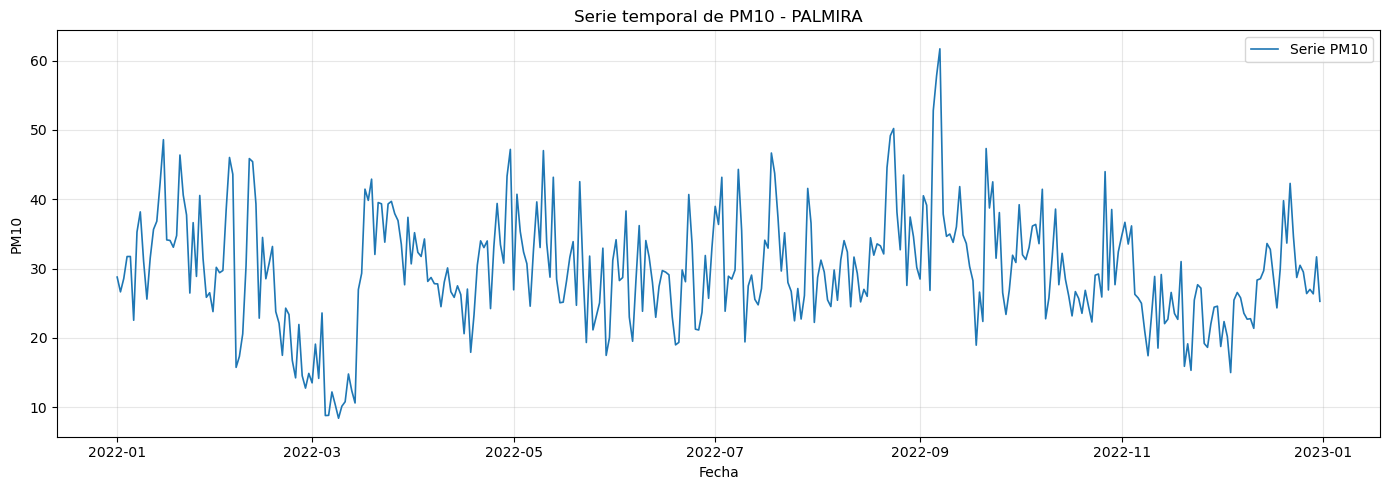

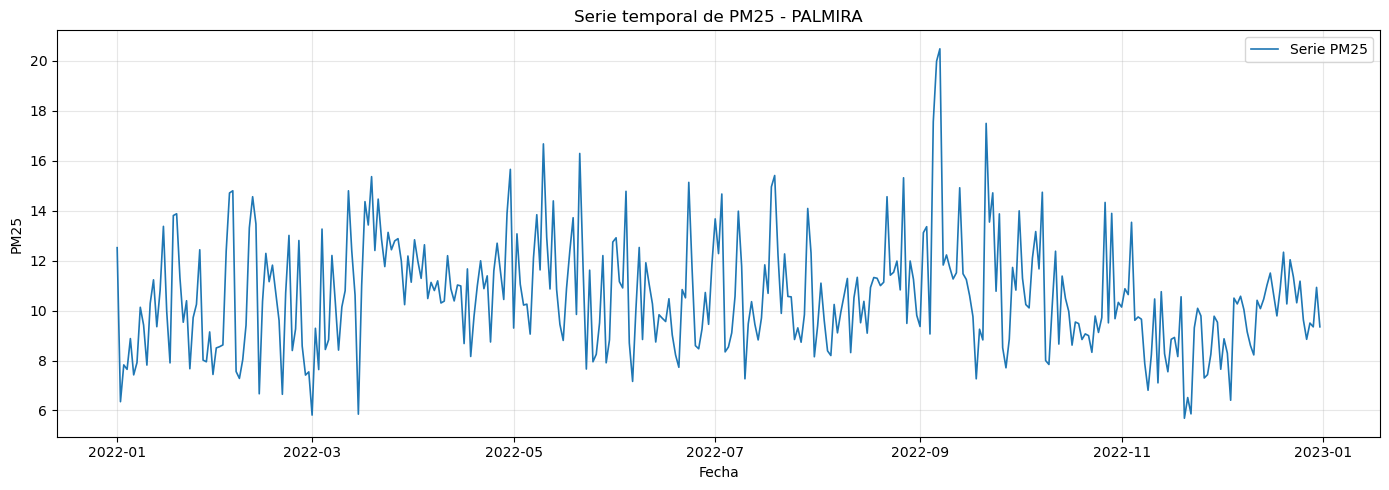

In [8]:
# ============================================================
# GRÁFICAS INICIALES DE SERIES DE TIEMPO
# ============================================================

for target in [t for t in TARGETS_A_EVALUAR if t in df_master.columns]:
    for estacion, sub in df_master.groupby("Estacion"):
        sub = sub.sort_values("Fecha inicial")
        if sub[target].notna().sum() < 30:
            continue

        plt.figure(figsize=(14, 5))
        plt.plot(sub["Fecha inicial"], sub[target], label=f"Serie {target}", linewidth=1.2)
        plt.title(f"Serie temporal de {target} - {estacion}")
        plt.xlabel("Fecha")
        plt.ylabel(target)
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()

        nombre_seguro = re.sub(r"[^A-Za-z0-9_]+", "_", f"serie_original_{target}_{estacion}")
        plt.savefig(GRAFICAS_DIR / f"{nombre_seguro}.png", dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()


## Protocolo de evaluación temporal para tesis

Este notebook usa un protocolo homogéneo para comparar los modelos de predicción de PM10 y PM2.5.

### Escenarios evaluados

1. **Sensibilidad a la partición temporal** con predicción a **1 día**:
   - 60 % entrenamiento / 40 % prueba.
   - 70 % entrenamiento / 30 % prueba.
   - 80 % entrenamiento / 20 % prueba.
   - 90 % entrenamiento / 10 % prueba.

2. **Horizontes directos de predicción**:
   - 7 días.
   - 30 días.
   - 90 días.

   Para aislar el efecto del horizonte, estos tres escenarios usan como referencia una partición nominal 80 % / 20 %.

### Controles metodológicos

- Las particiones son **cronológicas**; no se mezclan observaciones futuras con pasadas.
- Para un horizonte \(h\), la variable objetivo es \(y_{t+h}\); por tanto, 7, 30 y 90 días son **horizontes reales de pronóstico**, no solamente tamaños del conjunto de prueba.
- Se aplica una **purga temporal (gap) de \(h\) días** entre entrenamiento y prueba, y también dentro de la validación cruzada temporal.
- No se usa `bfill` ni interpolación bidireccional dentro de la etapa de modelado.
- Se incluye una línea base de **persistencia**: \(\hat{y}_{t+h}=y_t\).
- La selección de hiperparámetros se realiza únicamente con el conjunto de entrenamiento.
- Se registran por escenario los tiempos de validación, entrenamiento final, predicción y tiempo total.
- Se reportan MAE, RMSE, R², MAPE, sMAPE, WAPE, sesgo medio y mejora de RMSE frente a persistencia.

> **Nota:** debido a la purga temporal, el porcentaje efectivo de entrenamiento puede ser ligeramente inferior al porcentaje nominal. Ambos valores se reportan en las tablas finales.


In [9]:

# ============================================================
# 9. CONFIGURACIÓN DEL PROTOCOLO - RED NEURONAL MLP
# ============================================================

import json
import re
import platform
import sklearn
import matplotlib

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE_MLP = 42
N_FOLDS_MLP = 5
TRAIN_FRAC_HORIZONTES = 0.80
MIN_TRAIN_MLP = 120
MIN_TEST_MLP = 20
CLIP_PREDICCIONES_CERO = True

# Control de alineación temporal para evitar modelos visualmente "corridos".
CONTROL_ALINEACION_TEMPORAL = True
# Pesos del score de validación: RMSE 55%, MAE 15%, desfase 20%, R² 10%.
PESOS_SCORE_CV_ALINEADO = {"RMSE": 0.55, "MAE": 0.15, "LAG": 0.20, "R2": 0.10}
CALCULAR_IMPORTANCIA_PERMUTACION_MEJOR = True
N_REPEATS_IMPORTANCIA = 5

ESCENARIOS_MLP = [
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "60_40_H1", "Train_nominal": 0.60, "Horizonte_dias": 1, "Orden": 1},
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "70_30_H1", "Train_nominal": 0.70, "Horizonte_dias": 1, "Orden": 2},
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "80_20_H1", "Train_nominal": 0.80, "Horizonte_dias": 1, "Orden": 3},
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "90_10_H1", "Train_nominal": 0.90, "Horizonte_dias": 1, "Orden": 4},
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_7_dias_80_20", "Train_nominal": TRAIN_FRAC_HORIZONTES, "Horizonte_dias": 7, "Orden": 5},
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_30_dias_80_20", "Train_nominal": TRAIN_FRAC_HORIZONTES, "Horizonte_dias": 30, "Orden": 6},
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_90_dias_80_20", "Train_nominal": TRAIN_FRAC_HORIZONTES, "Horizonte_dias": 90, "Orden": 7},
]

# Grilla compacta y defendible para una tesis. El escalamiento se ajusta dentro de cada fold.
PARAM_GRID_MLP = [
    {
        "hidden_layer_sizes": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.0001,
        "learning_rate_init": 0.001,
        "max_iter": 1000,
        "early_stopping": False,
        "shuffle": True,
        "tol": 1e-4,
        "n_iter_no_change": 30,
    },
    {
        "hidden_layer_sizes": (128, 64),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.001,
        "learning_rate_init": 0.001,
        "max_iter": 1000,
        "early_stopping": False,
        "shuffle": True,
        "tol": 1e-4,
        "n_iter_no_change": 30,
    },
    {
        "hidden_layer_sizes": (128, 64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.001,
        "learning_rate_init": 0.0005,
        "max_iter": 1200,
        "early_stopping": False,
        "shuffle": True,
        "tol": 1e-4,
        "n_iter_no_change": 40,
    },
    {
        "hidden_layer_sizes": (128, 64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.01,
        "learning_rate_init": 0.0005,
        "max_iter": 1200,
        "early_stopping": False,
        "shuffle": True,
        "tol": 1e-4,
        "n_iter_no_change": 40,
    },
]

REZAGOS_TARGET_MLP = [1, 2, 3, 7, 14, 21, 30, 45, 60]
VENTANAS_TARGET_MLP = [3, 7, 14, 21, 30, 45, 60]
REZAGOS_COV_MLP = [1, 2, 3, 7, 14, 21, 30]
VENTANAS_COV_MLP = [3, 7, 14]

SALIDAS_MLP = Path("salidas_MLP_TESIS_PROTOCOLO_TEMPORAL")
GRAFICAS_MLP = SALIDAS_MLP / "graficas"
TABLAS_MLP = SALIDAS_MLP / "tablas"
MODELOS_MLP = SALIDAS_MLP / "modelos"
for carpeta in [SALIDAS_MLP, GRAFICAS_MLP, TABLAS_MLP, MODELOS_MLP]:
    carpeta.mkdir(parents=True, exist_ok=True)

versiones_mlp_df = pd.DataFrame([{
    "Python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "Semilla": RANDOM_STATE_MLP
}])

escenarios_mlp_df = pd.DataFrame(ESCENARIOS_MLP)
hiperparametros_mlp_df = pd.DataFrame(PARAM_GRID_MLP).reset_index().rename(columns={"index": "id_config"})

display(Markdown("## Escenarios de evaluación"))
display(escenarios_mlp_df)

display(Markdown("## Grilla candidata de hiperparámetros"))
display(hiperparametros_mlp_df)

display(Markdown("## Entorno de ejecución"))
display(versiones_mlp_df)


## Escenarios de evaluación

,Tipo_evaluacion,Escenario,Train_nominal,Horizonte_dias,Orden
0,Particion porcentual,60_40_H1,0.6,1,1
1,Particion porcentual,70_30_H1,0.7,1,2
2,Particion porcentual,80_20_H1,0.8,1,3
3,Particion porcentual,90_10_H1,0.9,1,4
4,Horizonte fijo,H_7_dias_80_20,0.8,7,5
5,Horizonte fijo,H_30_dias_80_20,0.8,30,6
6,Horizonte fijo,H_90_dias_80_20,0.8,90,7


## Grilla candidata de hiperparámetros

,id_config,hidden_layer_sizes,activation,solver,alpha,learning_rate_init,max_iter,early_stopping,shuffle,tol,n_iter_no_change
0,0,"(64, 32)",relu,adam,0.0001,0.0010,1000,False,True,0.0001,30
1,1,"(128, 64)",relu,adam,0.0010,0.0010,1000,False,True,0.0001,30
2,2,"(128, 64, 32)",relu,adam,0.0010,0.0005,1200,False,True,0.0001,40
3,3,"(128, 64, 32)",relu,adam,0.0100,0.0005,1200,False,True,0.0001,40


## Entorno de ejecución

,Python,numpy,pandas,scikit_learn,matplotlib,Semilla
0,3.13.5,2.1.3,2.2.3,1.6.1,3.10.0,42


In [10]:

# ============================================================
# 10. FUNCIONES DE PREPARACIÓN, MÉTRICAS Y VALIDACIÓN TEMPORAL
# ============================================================

def nombre_seguro_mlp(texto):
    return re.sub(r"[^A-Za-z0-9_-]+", "_", str(texto)).strip("_")


def calcular_metricas_tesis_mlp(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_real) & np.isfinite(y_pred)
    y_real, y_pred = y_real[mask], y_pred[mask]

    if len(y_real) == 0:
        return {k: np.nan for k in ["MAE", "RMSE", "R2", "MAPE_%", "sMAPE_%", "WAPE_%", "Sesgo_ME"]}

    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred) if len(y_real) > 1 else np.nan

    mask_mape = np.abs(y_real) > 1e-8
    mape = np.mean(np.abs((y_real[mask_mape] - y_pred[mask_mape]) / y_real[mask_mape])) * 100 if mask_mape.any() else np.nan

    denom_smape = np.abs(y_real) + np.abs(y_pred)
    smape = np.mean(np.where(denom_smape > 1e-8, 2 * np.abs(y_pred - y_real) / denom_smape, np.nan)) * 100

    denom_wape = np.sum(np.abs(y_real))
    wape = (np.sum(np.abs(y_real - y_pred)) / denom_wape) * 100 if denom_wape > 1e-8 else np.nan
    sesgo = np.mean(y_pred - y_real)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE_%": mape,
        "sMAPE_%": smape,
        "WAPE_%": wape,
        "Sesgo_ME": sesgo,
    }


def preparar_supervisado_mlp(df_estacion, target, covariables, horizonte):
    df = df_estacion.copy()
    df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")
    df = df.dropna(subset=["Fecha inicial"]).sort_values("Fecha inicial")
    df = df.drop_duplicates(subset=["Fecha inicial"], keep="last").set_index("Fecha inicial").asfreq("D")

    columnas_numericas = [c for c in [target] + covariables if c in df.columns]
    df[columnas_numericas] = df[columnas_numericas].apply(pd.to_numeric, errors="coerce")

    df["Fecha_objetivo"] = df.index + pd.to_timedelta(horizonte, unit="D")
    df["y_futuro"] = df[target].shift(-horizonte)
    df[f"{target}_t0"] = df[target]

    for lag in REZAGOS_TARGET_MLP:
        df[f"{target}_lag_{lag}"] = df[target].shift(lag)

    for ventana in VENTANAS_TARGET_MLP:
        r = df[target].rolling(ventana, min_periods=ventana)
        df[f"{target}_media_{ventana}"] = r.mean()
        df[f"{target}_std_{ventana}"] = r.std()
        df[f"{target}_min_{ventana}"] = r.min()
        df[f"{target}_max_{ventana}"] = r.max()

    df[f"{target}_diff_1"] = df[target] - df[target].shift(1)
    df[f"{target}_diff_7"] = df[target] - df[target].shift(7)

    fecha_obj = pd.DatetimeIndex(df["Fecha_objetivo"])
    df["dow_obj_sin"] = np.sin(2 * np.pi * fecha_obj.dayofweek / 7)
    df["dow_obj_cos"] = np.cos(2 * np.pi * fecha_obj.dayofweek / 7)
    df["doy_obj_sin"] = np.sin(2 * np.pi * fecha_obj.dayofyear / 365.25)
    df["doy_obj_cos"] = np.cos(2 * np.pi * fecha_obj.dayofyear / 365.25)

    covs_modelo = [c for c in covariables if c in df.columns]

    if "DViento" in covs_modelo:
        df["DViento_sin_t0"] = np.sin(np.deg2rad(df["DViento"]))
        df["DViento_cos_t0"] = np.cos(np.deg2rad(df["DViento"]))

    for cov in covs_modelo:
        df[f"{cov}_t0"] = df[cov]
        for lag in REZAGOS_COV_MLP:
            df[f"{cov}_lag_{lag}"] = df[cov].shift(lag)
        for ventana in VENTANAS_COV_MLP:
            df[f"{cov}_media_{ventana}"] = df[cov].rolling(ventana, min_periods=ventana).mean()

    features = [f"{target}_t0"]
    features += [c for c in df.columns if c.startswith(f"{target}_lag_")]
    features += [c for c in df.columns if c.startswith(f"{target}_media_") or c.startswith(f"{target}_std_") or c.startswith(f"{target}_min_") or c.startswith(f"{target}_max_")]
    features += [f"{target}_diff_1", f"{target}_diff_7"]
    features += ["dow_obj_sin", "dow_obj_cos", "doy_obj_sin", "doy_obj_cos"]
    features += [c for c in df.columns if c.endswith("_t0") and c != f"{target}_t0"]
    features += [c for c in df.columns if "_lag_" in c and not c.startswith(f"{target}_lag_")]
    features += [c for c in df.columns if "_media_" in c and not c.startswith(f"{target}_media_")]

    features = list(dict.fromkeys([c for c in features if c in df.columns]))
    data = df[features + ["y_futuro", "Fecha_objetivo"]].replace([np.inf, -np.inf], np.nan).dropna().copy()
    features = [c for c in features if data[c].nunique(dropna=True) > 1]
    data = data[features + ["y_futuro", "Fecha_objetivo"]].copy()

    X = data[features]
    y = data["y_futuro"]
    meta = pd.DataFrame({
        "Fecha_origen": data.index,
        "Fecha_objetivo": pd.to_datetime(data["Fecha_objetivo"].values),
        "Persistencia": data[f"{target}_t0"].values,
    }, index=data.index)

    return X, y, meta, features


def dividir_holdout_purgado_mlp(X, y, meta, train_frac, horizonte):
    n = len(X)
    n_test = max(MIN_TEST_MLP, int(np.ceil(n * (1 - train_frac))))
    test_start = n - n_test
    gap = int(max(1, horizonte))
    train_end = test_start - gap

    min_train_requerido = max(MIN_TRAIN_MLP, int(horizonte) + 80)
    if train_end < min_train_requerido or test_start >= n:
        return None

    return {
        "X_train": X.iloc[:train_end].copy(),
        "y_train": y.iloc[:train_end].copy(),
        "meta_train": meta.iloc[:train_end].copy(),
        "X_test": X.iloc[test_start:].copy(),
        "y_test": y.iloc[test_start:].copy(),
        "meta_test": meta.iloc[test_start:].copy(),
        "N_gap": gap,
        "Train_efectivo_%": train_end / n * 100,
        "Test_efectivo_%": (n - test_start) / n * 100,
    }


def construir_mlp_tesis(params):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(
            **params,
            random_state=RANDOM_STATE_MLP
        ))
    ])



def crear_tscv_seguro_mlp(n_muestras, horizonte, max_splits=N_FOLDS_MLP, min_train_cv=60, min_val_cv=10):
    gap = int(max(1, horizonte))
    for n_splits in range(min(max_splits, 5), 1, -1):
        max_test_size = (n_muestras - gap - min_train_cv) // n_splits
        if max_test_size >= min_val_cv:
            test_size = int(min(60, max_test_size))
            return TimeSeriesSplit(n_splits=n_splits, gap=gap, test_size=test_size)
    raise ValueError(
        f"No hay suficientes datos para validación temporal con gap={gap}. "
        f"N entrenamiento={n_muestras}."
    )




def max_lag_diagnostico_mlp(horizonte, n=None):
    """Máximo desfase a explorar solo con fines diagnósticos."""
    h = int(max(1, horizonte))
    base_lag = 7 if h <= 7 else (14 if h <= 30 else 30)
    if n is not None:
        base_lag = min(base_lag, max(1, int(n) // 4))
    return int(max(1, base_lag))


def diagnosticar_desfase_temporal_mlp(y_real, y_pred, horizonte=1):
    """
    Evalúa la alineación temporal SIN modificar la predicción original.

    Convención de Lag_optimo_dias:
    - 0: máxima correlación sin desplazar la predicción (deseable).
    - positivo: para maximizar correlación habría que mover la predicción hacia fechas posteriores.
    - negativo: para maximizar correlación habría que mover la predicción hacia fechas anteriores.

    El desplazamiento se reporta únicamente como diagnóstico; nunca se usa para
    recalcular las métricas de prueba ni para presentar una predicción corregida a posteriori.
    """
    real = pd.Series(np.asarray(y_real, dtype=float)).reset_index(drop=True)
    pred = pd.Series(np.asarray(y_pred, dtype=float)).reset_index(drop=True)
    n = min(len(real), len(pred))
    real, pred = real.iloc[:n], pred.iloc[:n]

    if n < 4:
        return {
            "Lag_optimo_dias": np.nan,
            "Lag_abs_dias": np.nan,
            "Correlacion_lag0": np.nan,
            "Correlacion_max_desfase": np.nan,
        }

    max_lag = max_lag_diagnostico_mlp(horizonte, n=n)
    registros = []
    for lag in range(-max_lag, max_lag + 1):
        pred_shift = pred.shift(lag)
        valido = real.notna() & pred_shift.notna()
        if valido.sum() < 4 or real[valido].nunique() < 2 or pred_shift[valido].nunique() < 2:
            corr = np.nan
        else:
            corr = real[valido].corr(pred_shift[valido])
        registros.append((lag, corr))

    corr0 = next((c for l, c in registros if l == 0), np.nan)
    validos = [(l, c) for l, c in registros if np.isfinite(c)]
    if not validos:
        lag_opt, corr_max = np.nan, np.nan
    else:
        # Si hay empate, se prefiere el menor |lag| y finalmente lag=0.
        lag_opt, corr_max = max(validos, key=lambda z: (z[1], -abs(z[0]), z[0] == 0))

    return {
        "Lag_optimo_dias": float(lag_opt) if np.isfinite(lag_opt) else np.nan,
        "Lag_abs_dias": float(abs(lag_opt)) if np.isfinite(lag_opt) else np.nan,
        "Correlacion_lag0": float(corr0) if np.isfinite(corr0) else np.nan,
        "Correlacion_max_desfase": float(corr_max) if np.isfinite(corr_max) else np.nan,
    }


def _minmax_seguro_mlp(serie, menor_es_mejor=True):
    s = pd.to_numeric(pd.Series(serie), errors="coerce")
    if s.notna().sum() == 0:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    minimo, maximo = s.min(), s.max()
    if not np.isfinite(minimo) or not np.isfinite(maximo) or np.isclose(minimo, maximo):
        norm = pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    else:
        norm = (s - minimo) / (maximo - minimo)
    if not menor_es_mejor:
        norm = 1 - norm
    return norm.fillna(1.0)


def agregar_score_alineado_cv_mlp(resumen):
    """
    Score de selección construido EXCLUSIVAMENTE con validación temporal.
    Menor es mejor. Prima el error, pero se penaliza una predicción temporalmente corrida.
    """
    r = resumen.copy()
    r["_rmse_n"] = _minmax_seguro_mlp(r["RMSE_CV"], True)
    r["_mae_n"] = _minmax_seguro_mlp(r["MAE_CV"], True)
    r["_lag_n"] = _minmax_seguro_mlp(r["Lag_abs_CV"], True)
    r["_r2_n"] = _minmax_seguro_mlp(r["R2_CV"], False)
    r["Score_CV_alineado"] = (
        0.55 * r["_rmse_n"] +
        0.15 * r["_mae_n"] +
        0.20 * r["_lag_n"] +
        0.10 * r["_r2_n"]
    )
    return r.drop(columns=["_rmse_n", "_mae_n", "_lag_n", "_r2_n"])


def seleccionar_mlp_temporal(X_train, y_train, horizonte):
    cv = crear_tscv_seguro_mlp(len(X_train), horizonte)
    filas = []
    inicio_cv = time.perf_counter()

    for id_config, params in enumerate(PARAM_GRID_MLP):
        for fold, (idx_tr, idx_val) in enumerate(cv.split(X_train), start=1):
            X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
            y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]

            modelo = construir_mlp_tesis(params)
            modelo.fit(X_tr, y_tr)
            pred = modelo.predict(X_val)
            if CLIP_PREDICCIONES_CERO:
                pred = np.clip(pred, 0, None)

            met = calcular_metricas_tesis_mlp(y_val, pred)
            diag = diagnosticar_desfase_temporal_mlp(y_val, pred, horizonte)
            filas.append({
                "id_config": id_config,
                "Fold": fold,
                "RMSE": met["RMSE"],
                "MAE": met["MAE"],
                "R2": met["R2"],
                "Iteraciones": getattr(modelo.named_steps["mlp"], "n_iter_", np.nan),
                **diag,
            })

    tiempo_cv = time.perf_counter() - inicio_cv
    cv_folds = pd.DataFrame(filas)

    resumen = (
        cv_folds.groupby("id_config", as_index=False)
        .agg(
            RMSE_CV=("RMSE", "mean"),
            RMSE_CV_std=("RMSE", "std"),
            MAE_CV=("MAE", "mean"),
            R2_CV=("R2", "mean"),
            Iteraciones_promedio=("Iteraciones", "mean"),
            Lag_abs_CV=("Lag_abs_dias", "mean"),
            Lag_optimo_CV_mediana=("Lag_optimo_dias", "median"),
            Correlacion_lag0_CV=("Correlacion_lag0", "mean"),
            Correlacion_max_CV=("Correlacion_max_desfase", "mean"),
            N_folds=("Fold", "nunique"),
        )
        .reset_index(drop=True)
    )
    resumen = agregar_score_alineado_cv_mlp(resumen)
    resumen = resumen.sort_values(
        ["Score_CV_alineado", "RMSE_CV", "Lag_abs_CV", "R2_CV"],
        ascending=[True, True, True, False]
    ).reset_index(drop=True)

    mejor_id = int(resumen.iloc[0]["id_config"])
    return PARAM_GRID_MLP[mejor_id].copy(), resumen, cv_folds, tiempo_cv



In [11]:

# ============================================================
# 11. ENTRENAMIENTO Y EVALUACIÓN DE TODOS LOS ESCENARIOS
# ============================================================

base_mlp = df_master.copy()
base_mlp["Fecha inicial"] = pd.to_datetime(base_mlp["Fecha inicial"], errors="coerce")

targets_mlp = [c for c in ["PM10", "PM25", "PM2.5"] if c in base_mlp.columns]
if "PM25" in targets_mlp and "PM2.5" in targets_mlp:
    targets_mlp.remove("PM2.5")

covariables_mlp = [
    "DViento", "VViento", "HAire2", "HAire10", "TAire2", "TAire10",
    "TMPR_AIR_10CM", "P", "PLiquida", "RGlobal", "RUVb"
]
covariables_mlp = [c for c in covariables_mlp if c in base_mlp.columns]

metricas_mlp = []
predicciones_mlp = []
tiempos_mlp = []
cv_resumen_mlp = []
cv_folds_mlp = []
auditoria_mlp = []
modelos_mlp = {}
objetos_prueba_mlp = {}

for estacion, df_est in base_mlp.groupby("Estacion"):
    for target in targets_mlp:
        for esc in ESCENARIOS_MLP:
            h = int(esc["Horizonte_dias"])
            inicio_total = time.perf_counter()

            X, y, meta, features = preparar_supervisado_mlp(
                df_estacion=df_est,
                target=target,
                covariables=covariables_mlp,
                horizonte=h
            )

            auditoria_mlp.append({
                "Estacion": estacion,
                "Variable": target,
                "Escenario": esc["Escenario"],
                "Horizonte_dias": h,
                "N_supervisado": len(X),
                "N_features": len(features),
                "Fecha_origen_min": meta["Fecha_origen"].min() if len(meta) else pd.NaT,
                "Fecha_origen_max": meta["Fecha_origen"].max() if len(meta) else pd.NaT,
                "Fecha_objetivo_min": meta["Fecha_objetivo"].min() if len(meta) else pd.NaT,
                "Fecha_objetivo_max": meta["Fecha_objetivo"].max() if len(meta) else pd.NaT,
            })

            split = dividir_holdout_purgado_mlp(X, y, meta, esc["Train_nominal"], h)
            if split is None:
                print(f"Omitido por datos insuficientes: {estacion} | {target} | {esc['Escenario']}")
                continue

            X_train, y_train = split["X_train"], split["y_train"]
            X_test, y_test = split["X_test"], split["y_test"]
            meta_train, meta_test = split["meta_train"], split["meta_test"]

            mejores_params, resumen_cv, folds_cv, tiempo_cv = seleccionar_mlp_temporal(
                X_train, y_train, h
            )

            inicio_fit = time.perf_counter()
            modelo = construir_mlp_tesis(mejores_params)
            modelo.fit(X_train, y_train)
            tiempo_fit = time.perf_counter() - inicio_fit

            inicio_pred = time.perf_counter()
            pred_train = modelo.predict(X_train)
            pred_test = modelo.predict(X_test)
            if CLIP_PREDICCIONES_CERO:
                pred_train = np.clip(pred_train, 0, None)
                pred_test = np.clip(pred_test, 0, None)
            tiempo_pred = time.perf_counter() - inicio_pred

            met_train = calcular_metricas_tesis_mlp(y_train, pred_train)
            met_test = calcular_metricas_tesis_mlp(y_test, pred_test)
            met_base = calcular_metricas_tesis_mlp(y_test, meta_test["Persistencia"].values)

            # Alineación temporal: diagnóstico sin desplazar la predicción.
            diag_train_mlp = diagnosticar_desfase_temporal_mlp(y_train, pred_train, h)
            diag_test_mlp = diagnosticar_desfase_temporal_mlp(y_test, pred_test, h)

            mejora_rmse = ((met_base["RMSE"] - met_test["RMSE"]) / met_base["RMSE"] * 100
                           if np.isfinite(met_base["RMSE"]) and met_base["RMSE"] > 0 else np.nan)

            mejor_cv = resumen_cv.iloc[0]
            config_json = json.dumps(mejores_params, ensure_ascii=False, sort_keys=True)
            tiempo_total = time.perf_counter() - inicio_total
            n_iter_final = getattr(modelo.named_steps["mlp"], "n_iter_", np.nan)

            base_fila = {
                "Modelo": "Red Neuronal MLP",
                "Estacion": estacion,
                "Variable": target,
                "Tipo_evaluacion": esc["Tipo_evaluacion"],
                "Escenario": esc["Escenario"],
                "Orden_escenario": esc["Orden"],
                "Horizonte_dias": h,
                "Train_nominal_%": esc["Train_nominal"] * 100,
                "Train_efectivo_%": split["Train_efectivo_%"],
                "Test_efectivo_%": split["Test_efectivo_%"],
                "Gap_purga_dias": split["N_gap"],
                "N_features": len(features),
                "Iteraciones_MLP": n_iter_final,
                "Hiperparametros_seleccionados": config_json,
            }

            metricas_mlp.append({
                **base_fila, "Etapa": "Entrenamiento",
                "N_registros": len(y_train),
                "Fecha_inicio": meta_train["Fecha_objetivo"].min(),
                "Fecha_fin": meta_train["Fecha_objetivo"].max(),
                **met_train,
                **diag_train_mlp,
                "RMSE_persistencia": np.nan,
                "Mejora_RMSE_vs_persistencia_%": np.nan,
            })
            metricas_mlp.append({
                **base_fila, "Etapa": "Prueba",
                "N_registros": len(y_test),
                "Fecha_inicio": meta_test["Fecha_objetivo"].min(),
                "Fecha_fin": meta_test["Fecha_objetivo"].max(),
                **met_test,
                **diag_test_mlp,
                "RMSE_persistencia": met_base["RMSE"],
                "Mejora_RMSE_vs_persistencia_%": mejora_rmse,
            })

            predicciones_mlp.append(pd.DataFrame({
                "Modelo": "Red Neuronal MLP",
                "Estacion": estacion,
                "Variable": target,
                "Tipo_evaluacion": esc["Tipo_evaluacion"],
                "Escenario": esc["Escenario"],
                "Horizonte_dias": h,
                "Fecha_origen": meta_test["Fecha_origen"].values,
                "Fecha_objetivo": meta_test["Fecha_objetivo"].values,
                "Real": y_test.values,
                "Prediccion": pred_test,
                "Persistencia": meta_test["Persistencia"].values,
                "Error": y_test.values - pred_test,
                "Error_absoluto": np.abs(y_test.values - pred_test),
            }))

            tiempos_mlp.append({
                "Modelo": "Red Neuronal MLP",
                "Estacion": estacion,
                "Variable": target,
                "Tipo_evaluacion": esc["Tipo_evaluacion"],
                "Escenario": esc["Escenario"],
                "Orden_escenario": esc["Orden"],
                "Horizonte_dias": h,
                "Train_nominal_%": esc["Train_nominal"] * 100,
                "Train_efectivo_%": split["Train_efectivo_%"],
                "Test_efectivo_%": split["Test_efectivo_%"],
                "Gap_purga_dias": split["N_gap"],
                "N_train": len(y_train),
                "N_test": len(y_test),
                "N_features": len(features),
                "Iteraciones_MLP": n_iter_final,
                "Hiperparametros_seleccionados": config_json,
                "RMSE_CV_mejor": mejor_cv["RMSE_CV"],
                "R2_CV_mejor": mejor_cv["R2_CV"],
                "Lag_abs_CV_mejor": mejor_cv.get("Lag_abs_CV", np.nan),
                "Lag_optimo_CV_mediana": mejor_cv.get("Lag_optimo_CV_mediana", np.nan),
                "Correlacion_lag0_CV_mejor": mejor_cv.get("Correlacion_lag0_CV", np.nan),
                "Score_CV_alineado": mejor_cv.get("Score_CV_alineado", np.nan),
                "N_folds_CV": int(mejor_cv["N_folds"]),
                "Tiempo_validacion_CV_s": tiempo_cv,
                "Tiempo_entrenamiento_final_s": tiempo_fit,
                "Tiempo_prediccion_s": tiempo_pred,
                "Tiempo_total_escenario_s": tiempo_total,
                "Tiempo_total_escenario_min": tiempo_total / 60,
            })

            cv_resumen_mlp.append(
                resumen_cv.assign(
                    Estacion=estacion, Variable=target, Escenario=esc["Escenario"],
                    Horizonte_dias=h
                )
            )
            cv_folds_mlp.append(
                folds_cv.assign(
                    Estacion=estacion, Variable=target, Escenario=esc["Escenario"],
                    Horizonte_dias=h
                )
            )

            clave = (estacion, target, esc["Escenario"])
            modelos_mlp[clave] = modelo
            objetos_prueba_mlp[clave] = (X_test.copy(), y_test.copy())

            print(
                f"OK | {estacion} | {target} | {esc['Escenario']} | H={h} | "
                f"RMSE={met_test['RMSE']:.3f} | R2={met_test['R2']:.3f} | "
                f"Skill={mejora_rmse:.2f}% | {tiempo_total:.2f}s"
            )

metricas_mlp_df = pd.DataFrame(metricas_mlp)
predicciones_mlp_df = pd.concat(predicciones_mlp, ignore_index=True) if predicciones_mlp else pd.DataFrame()
tiempos_mlp_df = pd.DataFrame(tiempos_mlp)
cv_resumen_mlp_df = pd.concat(cv_resumen_mlp, ignore_index=True) if cv_resumen_mlp else pd.DataFrame()
cv_folds_mlp_df = pd.concat(cv_folds_mlp, ignore_index=True) if cv_folds_mlp else pd.DataFrame()
auditoria_mlp_df = pd.DataFrame(auditoria_mlp)


OK | PALMIRA | PM10 | 60_40_H1 | H=1 | RMSE=9.698 | R2=-0.503 | Skill=-33.27% | 33.36s
OK | PALMIRA | PM10 | 70_30_H1 | H=1 | RMSE=9.720 | R2=-1.521 | Skill=-56.60% | 38.22s
OK | PALMIRA | PM10 | 80_20_H1 | H=1 | RMSE=9.682 | R2=-1.759 | Skill=-81.16% | 46.18s
OK | PALMIRA | PM10 | 90_10_H1 | H=1 | RMSE=6.816 | R2=-0.432 | Skill=-41.74% | 47.87s
OK | PALMIRA | PM10 | H_7_dias_80_20 | H=7 | RMSE=11.745 | R2=-3.136 | Skill=-57.02% | 42.41s
OK | PALMIRA | PM10 | H_30_dias_80_20 | H=30 | RMSE=8.069 | R2=-1.085 | Skill=18.56% | 33.60s
Omitido por datos insuficientes: PALMIRA | PM10 | H_90_dias_80_20
OK | PALMIRA | PM25 | 60_40_H1 | H=1 | RMSE=5.291 | R2=-3.633 | Skill=-112.14% | 20.28s
OK | PALMIRA | PM25 | 70_30_H1 | H=1 | RMSE=5.252 | R2=-7.814 | Skill=-158.53% | 22.30s
OK | PALMIRA | PM25 | 80_20_H1 | H=1 | RMSE=5.658 | R2=-11.759 | Skill=-231.49% | 31.01s
OK | PALMIRA | PM25 | 90_10_H1 | H=1 | RMSE=2.076 | R2=-1.652 | Skill=-54.59% | 27.92s
OK | PALMIRA | PM25 | H_7_dias_80_20 | H=7 | R

## Tabla final de métricas — Red Neuronal MLP

,Modelo,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Train_efectivo_%,Test_efectivo_%,Gap_purga_dias,N_registros,MAE,RMSE,R2,sMAPE_%,WAPE_%,Sesgo_ME,Lag_optimo_dias,Lag_abs_dias,Correlacion_lag0,Correlacion_max_desfase,RMSE_persistencia,Mejora_RMSE_vs_persistencia_%
0,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,60_40_H1,1,60.0,59.5395,40.1316,1,122,7.7622,9.6984,-0.5025,24.1117,26.2870,5.5377,-4.0,4.0,0.5098,0.5207,7.2775,-33.2665
1,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,70_30_H1,1,70.0,69.4079,30.2632,1,92,8.1258,9.7198,-1.5206,29.8843,29.3939,-0.0118,6.0,6.0,-0.0090,0.1867,6.2069,-56.5975
2,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,80_20_H1,1,80.0,79.6053,20.0658,1,61,7.9088,9.6823,-1.7588,27.6387,30.1444,5.4073,7.0,7.0,0.0311,0.5420,5.3447,-81.1589
3,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,90_10_H1,1,90.0,89.4737,10.1974,1,31,5.8423,6.8157,-0.4319,20.6648,21.1503,2.4110,-7.0,7.0,0.1152,0.3628,4.8087,-41.7359
4,Red Neuronal MLP,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,77.5168,20.1342,7,60,10.0398,11.7453,-3.1364,33.4109,38.4723,8.9965,2.0,2.0,0.1352,0.4982,7.4802,-57.0189
5,Red Neuronal MLP,PM10,PALMIRA,Horizonte fijo,H_30_dias_80_20,30,80.0,69.0909,20.0000,30,55,6.6815,8.0693,-1.0847,24.1219,26.1123,5.4559,-8.0,8.0,0.3967,0.5104,9.9080,18.5584
6,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,60_40_H1,1,60.0,59.5395,40.1316,1,122,4.5252,5.2911,-3.6331,36.1857,43.6708,4.2843,7.0,7.0,0.2943,0.3492,2.4941,-112.1399
7,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,70_30_H1,1,70.0,69.4079,30.2632,1,92,4.3698,5.2519,-7.8143,37.5285,44.6062,2.8125,7.0,7.0,-0.1302,0.1159,2.0314,-158.5341
8,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,80_20_H1,1,80.0,79.6053,20.0658,1,61,4.8551,5.6582,-11.7585,40.4271,51.4354,4.3466,7.0,7.0,-0.0162,0.4840,1.7069,-231.4946
9,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,90_10_H1,1,90.0,89.4737,10.1974,1,31,1.6987,2.0758,-1.6523,16.7082,17.0709,0.3551,7.0,7.0,-0.0635,0.3579,1.3428,-54.5902


## Tabla final de tiempos, configuración e hiperparámetros — Red Neuronal MLP

,Modelo,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Train_efectivo_%,Test_efectivo_%,Gap_purga_dias,N_train,N_test,N_features,Iteraciones_MLP,Hiperparametros_seleccionados,RMSE_CV_mejor,R2_CV_mejor,Lag_abs_CV_mejor,Lag_optimo_CV_mediana,Correlacion_lag0_CV_mejor,Score_CV_alineado,N_folds_CV,Tiempo_validacion_CV_s,Tiempo_entrenamiento_final_s,Tiempo_prediccion_s,Tiempo_total_escenario_s,Tiempo_total_escenario_min
0,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,60_40_H1,1,60.0,59.5395,40.1316,1,181,122,112,634,"{""activation"": ""relu"", ""alpha"": 0.001, ""early_...",8.7342,-0.7824,3.0,-1.0,0.0757,0.3487,5,30.4301,2.7134,0.0075,33.3560,0.5559
1,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,70_30_H1,1,70.0,69.4079,30.2632,1,211,92,112,929,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",9.0088,-0.5484,2.8,-1.0,0.2558,0.1333,5,34.2904,3.7702,0.0063,38.2234,0.6371
2,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,80_20_H1,1,80.0,79.6053,20.0658,1,242,61,112,691,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",10.0276,-1.2976,3.2,-2.0,0.0371,0.0000,5,43.0146,2.9942,0.0064,46.1811,0.7697
3,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,90_10_H1,1,90.0,89.4737,10.1974,1,272,31,112,556,"{""activation"": ""relu"", ""alpha"": 0.001, ""early_...",9.3992,-0.7823,2.8,-1.0,0.1904,0.0000,5,43.4087,4.2853,0.0083,47.8662,0.7978
4,Red Neuronal MLP,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,77.5168,20.1342,7,231,60,112,683,"{""activation"": ""relu"", ""alpha"": 0.001, ""early_...",9.7281,-1.0474,4.8,-7.0,0.0600,0.0200,5,37.2074,5.0321,0.0076,42.4102,0.7068
5,Red Neuronal MLP,PM10,PALMIRA,Horizonte fijo,H_30_dias_80_20,30,80.0,69.0909,20.0000,30,190,55,112,662,"{""activation"": ""relu"", ""alpha"": 0.01, ""early_s...",11.6163,-1.9810,3.6,-1.0,-0.1070,0.2330,5,30.3561,3.0486,0.0091,33.6036,0.5601
6,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,60_40_H1,1,60.0,59.5395,40.1316,1,181,122,112,433,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",16.2329,-174.3599,2.8,1.0,0.0770,0.0000,5,18.9128,1.1761,0.0065,20.2763,0.3379
7,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,70_30_H1,1,70.0,69.4079,30.2632,1,211,92,112,515,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",17.2909,-194.2993,2.8,0.0,0.1378,0.0000,5,20.4815,1.6490,0.0064,22.2958,0.3716
8,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,80_20_H1,1,80.0,79.6053,20.0658,1,242,61,112,398,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",20.8890,-293.9730,3.6,1.0,0.0057,0.0000,5,29.1082,1.7505,0.0042,31.0081,0.5168
9,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,90_10_H1,1,90.0,89.4737,10.1974,1,272,31,112,395,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",20.5866,-304.5321,3.6,2.0,0.1139,0.0000,5,26.1368,1.6756,0.0054,27.9184,0.4653


## Mejor resultado observado por contaminante, estación y horizonte

,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,RMSE,MAE,R2,Lag_optimo_dias,Correlacion_lag0,Score_diagnostico_prueba,RMSE_persistencia,Mejora_RMSE_vs_persistencia_%
0,PM10,PALMIRA,Particion porcentual,90_10_H1,1,6.8157,5.8423,-0.4319,-7.0,0.1152,0.25,4.8087,-41.7359
1,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,11.7453,10.0398,-3.1364,2.0,0.1352,0.10,7.4802,-57.0189
2,PM10,PALMIRA,Horizonte fijo,H_30_dias_80_20,30,8.0693,6.6815,-1.0847,-8.0,0.3967,0.10,9.9080,18.5584
3,PM25,PALMIRA,Particion porcentual,90_10_H1,1,2.0758,1.6987,-1.6523,7.0,-0.0635,0.00,1.3428,-54.5902
4,PM25,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,5.0840,4.3453,-9.1649,6.0,0.1110,0.10,2.0607,-146.7131
5,PM25,PALMIRA,Horizonte fijo,H_30_dias_80_20,30,3.6043,2.8953,-4.4539,-8.0,0.4333,0.10,2.7162,-32.6931


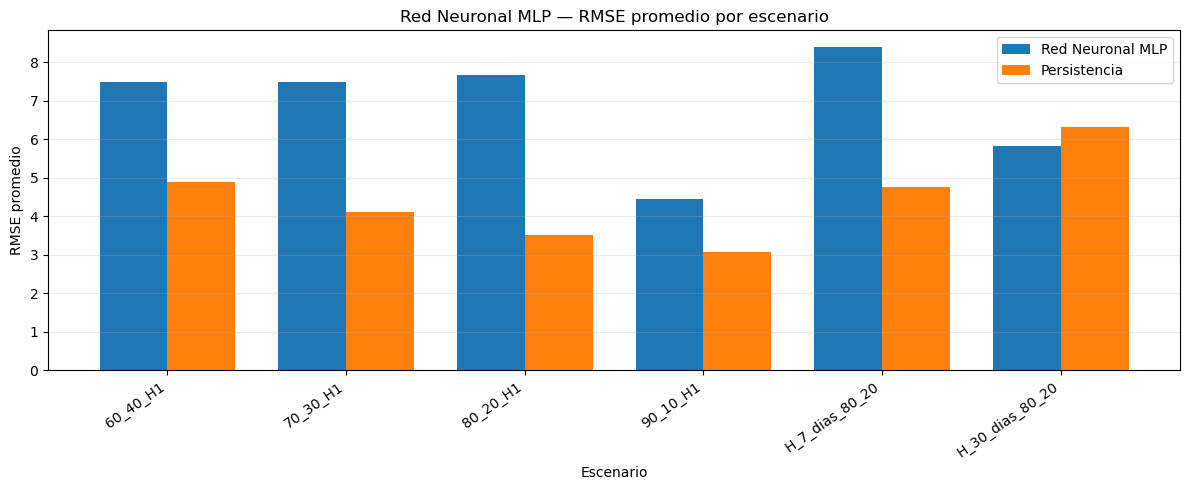

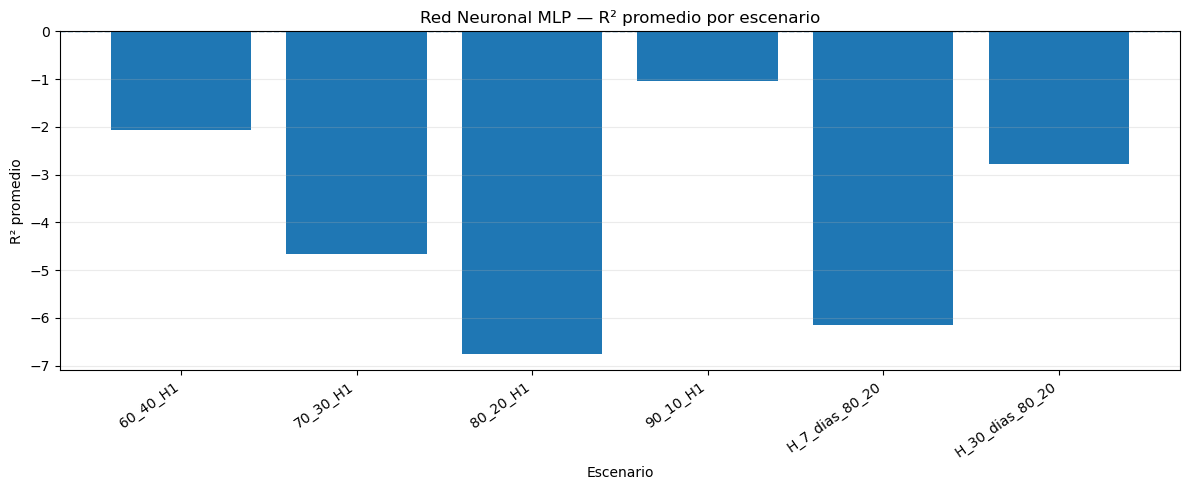

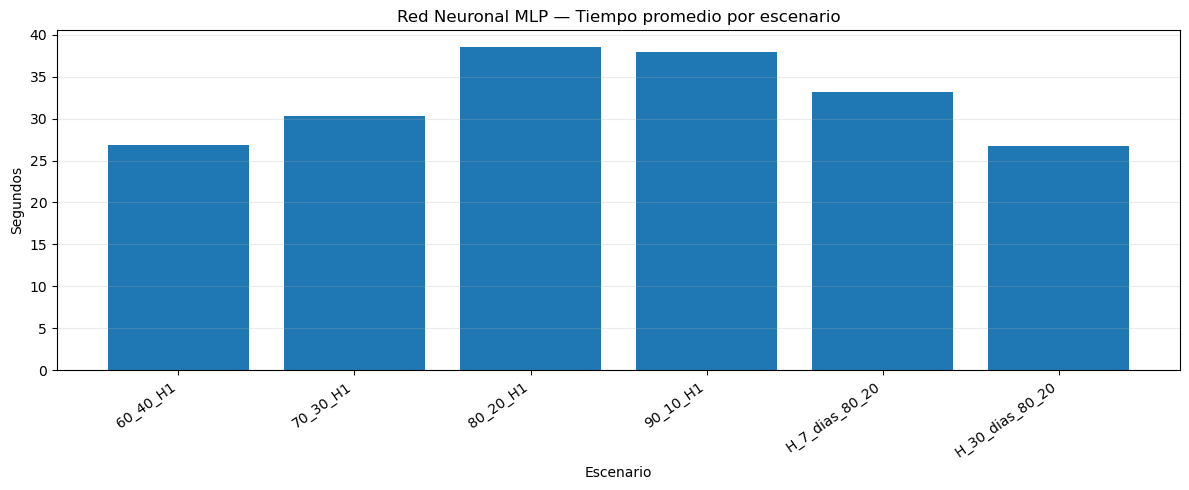

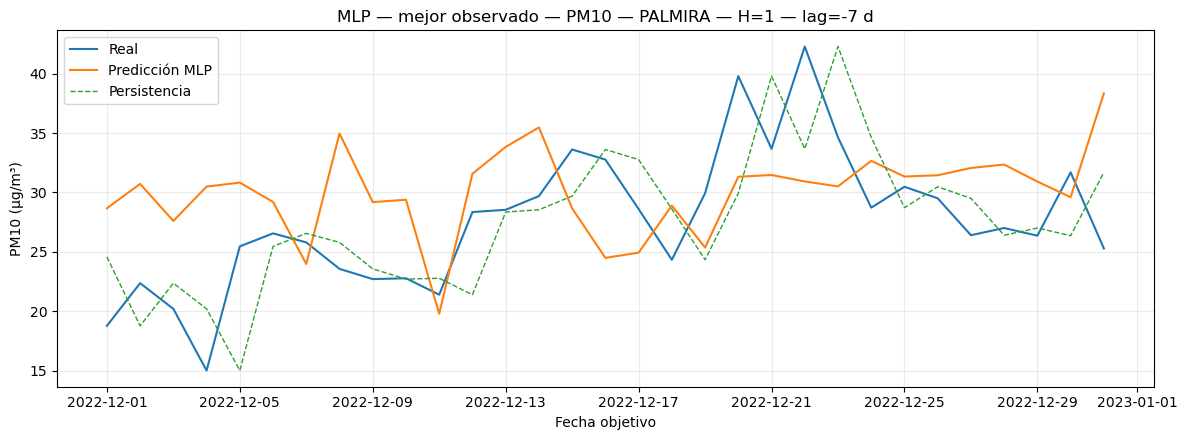

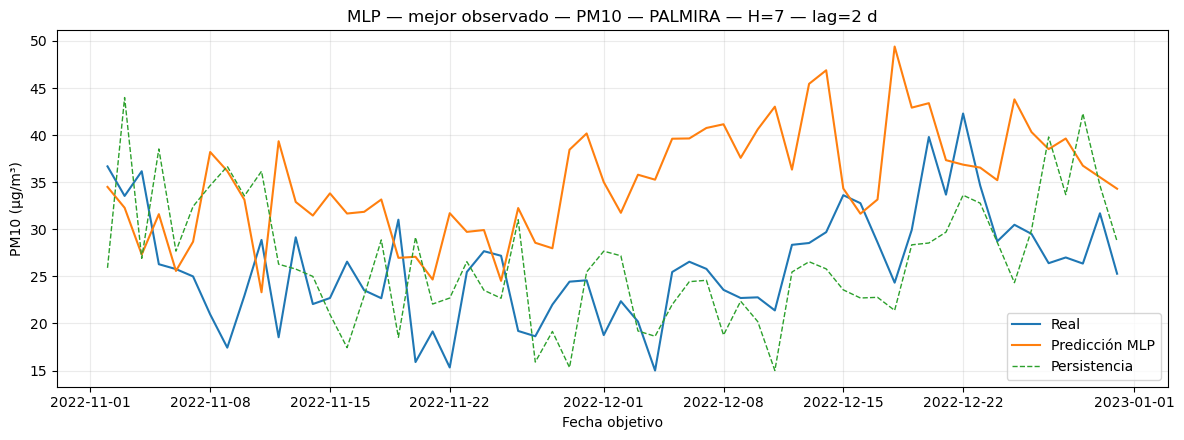

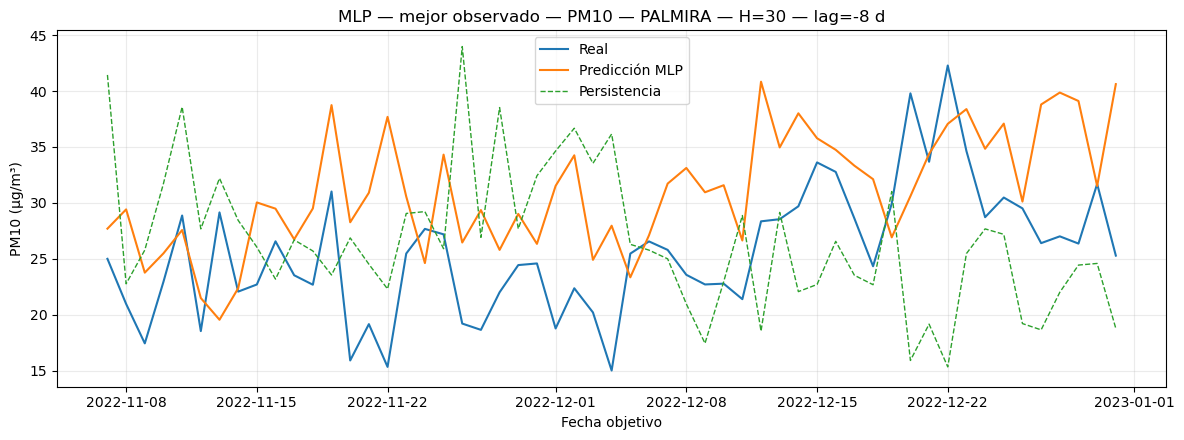

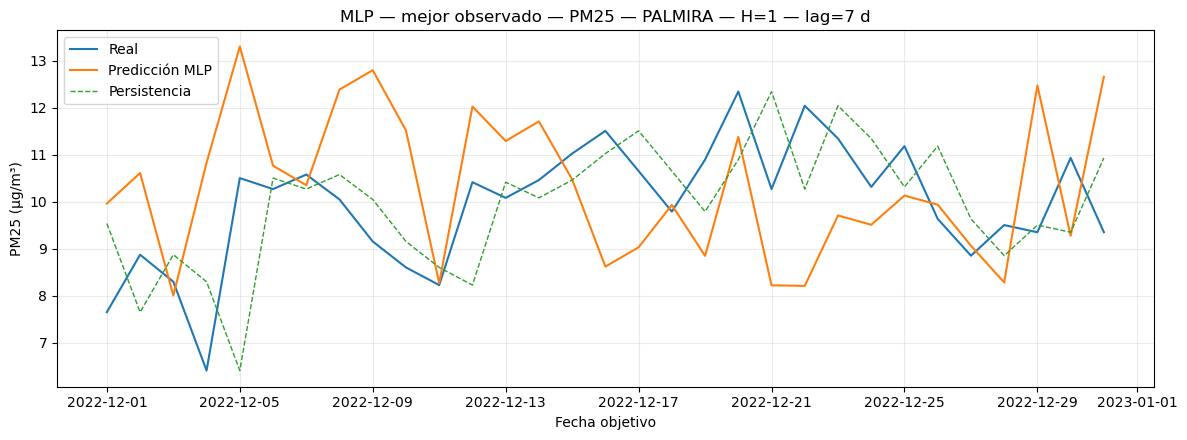

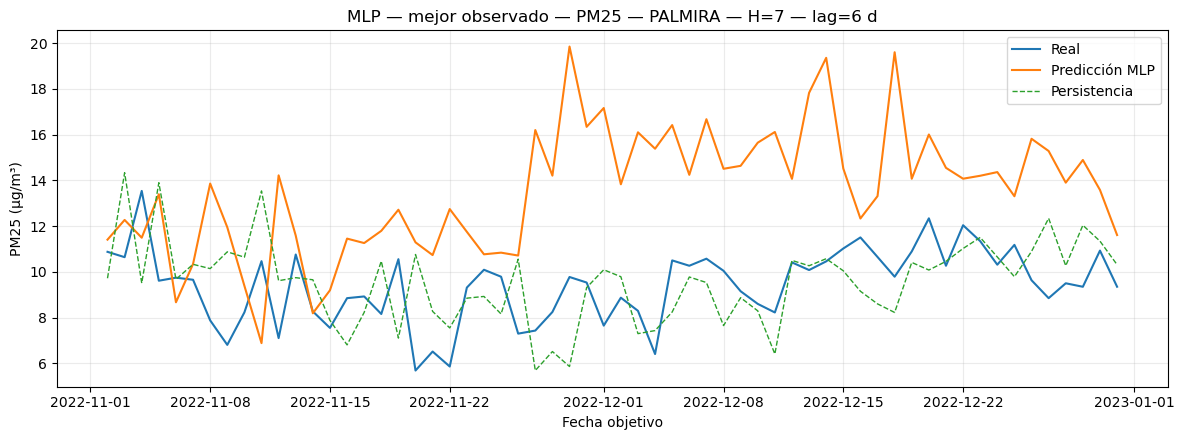

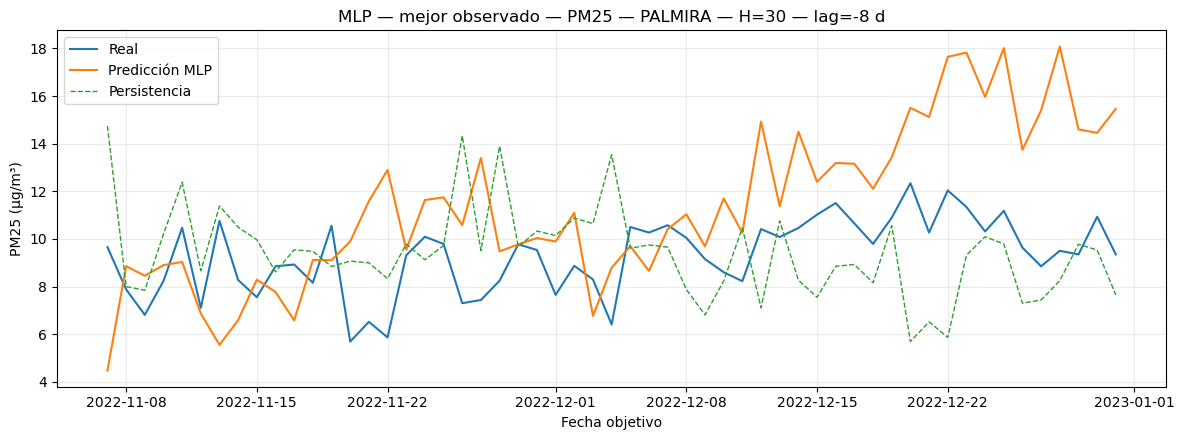

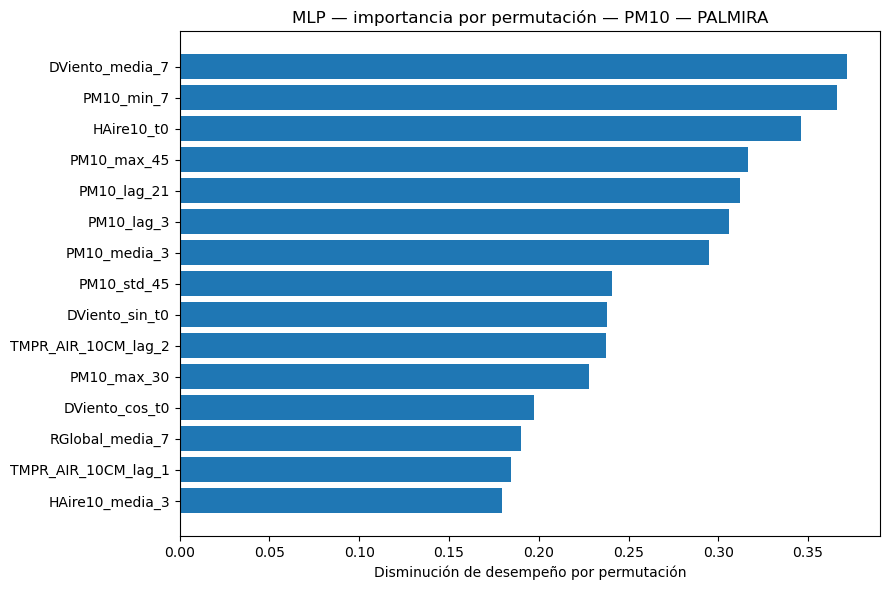

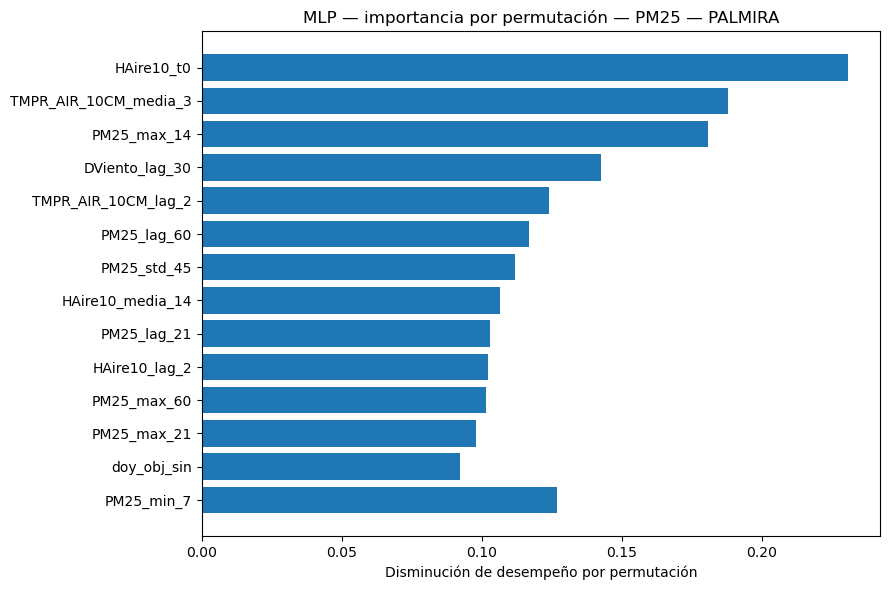

In [12]:

# ============================================================
# 12. TABLAS FINALES ORDENADAS, INTERPRETABILIDAD Y GRÁFICAS
# ============================================================

if metricas_mlp_df.empty:
    raise ValueError("No se generaron resultados de la Red Neuronal MLP. Revisa la disponibilidad de datos.")

metricas_prueba_mlp_df = (
    metricas_mlp_df[metricas_mlp_df["Etapa"] == "Prueba"]
    .sort_values(["Variable", "Estacion", "Orden_escenario"])
    .reset_index(drop=True)
)

tiempos_mlp_df = (
    tiempos_mlp_df
    .sort_values(["Variable", "Estacion", "Orden_escenario"])
    .reset_index(drop=True)
)

columnas_tabla_tesis = [
    "Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario",
    "Horizonte_dias", "Train_nominal_%", "Train_efectivo_%",
    "Test_efectivo_%", "Gap_purga_dias", "N_registros",
    "MAE", "RMSE", "R2", "sMAPE_%", "WAPE_%", "Sesgo_ME",
    "Lag_optimo_dias", "Lag_abs_dias", "Correlacion_lag0", "Correlacion_max_desfase",
    "RMSE_persistencia", "Mejora_RMSE_vs_persistencia_%"
]
tabla_metricas_tesis_mlp = metricas_prueba_mlp_df[
    [c for c in columnas_tabla_tesis if c in metricas_prueba_mlp_df.columns]
].copy()

columnas_tiempo_tesis = [
    "Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario",
    "Horizonte_dias", "Train_nominal_%", "Train_efectivo_%",
    "Test_efectivo_%", "Gap_purga_dias", "N_train", "N_test", "N_features",
    "Iteraciones_MLP", "Hiperparametros_seleccionados", "RMSE_CV_mejor", "R2_CV_mejor", "Lag_abs_CV_mejor", "Lag_optimo_CV_mediana",
    "Correlacion_lag0_CV_mejor", "Score_CV_alineado", "N_folds_CV",
    "Tiempo_validacion_CV_s", "Tiempo_entrenamiento_final_s",
    "Tiempo_prediccion_s", "Tiempo_total_escenario_s",
    "Tiempo_total_escenario_min"
]
tabla_tiempos_tesis_mlp = tiempos_mlp_df[
    [c for c in columnas_tiempo_tesis if c in tiempos_mlp_df.columns]
].copy()

display(Markdown("## Tabla final de métricas — Red Neuronal MLP"))
display(tabla_metricas_tesis_mlp.round(4))

display(Markdown("## Tabla final de tiempos, configuración e hiperparámetros — Red Neuronal MLP"))
display(tabla_tiempos_tesis_mlp.round(4))

# ------------------------------------------------------------
# Selección automática para visualización, separada por horizonte
# ------------------------------------------------------------
# IMPORTANTE: los hiperparámetros ya fueron elegidos únicamente mediante CV temporal.
# Este score usa la prueba SOLO para resumir cuál resultado observado se visualiza mejor;
# no reentrena ni altera la predicción.

def _score_diagnostico_prueba_mlp(grupo):
    g = grupo.copy()
    g["_rmse_n"] = _minmax_seguro_mlp(g["RMSE"], True)
    g["_mae_n"] = _minmax_seguro_mlp(g["MAE"], True)
    g["_lag_n"] = _minmax_seguro_mlp(g["Lag_abs_dias"], True)
    g["_r2_n"] = _minmax_seguro_mlp(g["R2"], False)
    g["Score_diagnostico_prueba"] = (
        0.50 * g["_rmse_n"] +
        0.15 * g["_mae_n"] +
        0.25 * g["_lag_n"] +
        0.10 * g["_r2_n"]
    )
    return g.drop(columns=["_rmse_n", "_mae_n", "_lag_n", "_r2_n"])

metricas_prueba_mlp_df = (
    metricas_prueba_mlp_df
    .groupby(["Variable", "Estacion", "Horizonte_dias"], group_keys=False)
    .apply(_score_diagnostico_prueba_mlp)
    .reset_index(drop=True)
)

mejor_mlp = (
    metricas_prueba_mlp_df
    .sort_values(
        ["Variable", "Estacion", "Horizonte_dias", "Score_diagnostico_prueba", "RMSE", "Lag_abs_dias", "R2"],
        ascending=[True, True, True, True, True, True, False]
    )
    .groupby(["Variable", "Estacion", "Horizonte_dias"], as_index=False)
    .first()
)

display(Markdown("## Mejor resultado observado por contaminante, estación y horizonte"))
display(mejor_mlp[[
    "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
    "RMSE", "MAE", "R2", "Lag_optimo_dias", "Correlacion_lag0",
    "Score_diagnostico_prueba", "RMSE_persistencia", "Mejora_RMSE_vs_persistencia_%"
]].round(4))

resumen_escenarios_mlp = (
    metricas_prueba_mlp_df
    .groupby(["Orden_escenario", "Tipo_evaluacion", "Escenario", "Horizonte_dias"], as_index=False)
    .agg(
        RMSE_promedio=("RMSE", "mean"),
        RMSE_persistencia_promedio=("RMSE_persistencia", "mean"),
        R2_promedio=("R2", "mean"),
        Skill_RMSE_promedio=("Mejora_RMSE_vs_persistencia_%", "mean"),
        N_resultados=("RMSE", "count"),
    )
    .sort_values("Orden_escenario")
)

tiempo_escenarios_mlp = (
    tiempos_mlp_df
    .groupby(["Orden_escenario", "Escenario", "Horizonte_dias"], as_index=False)
    .agg(
        Tiempo_total_promedio_s=("Tiempo_total_escenario_s", "mean"),
        Tiempo_total_acumulado_s=("Tiempo_total_escenario_s", "sum"),
    )
    .sort_values("Orden_escenario")
)

# Importancia por permutación solo en el mejor escenario de cada estación/contaminante.
importancias_mlp = []
if CALCULAR_IMPORTANCIA_PERMUTACION_MEJOR:
    for _, fila in mejor_mlp.iterrows():
        clave = (fila["Estacion"], fila["Variable"], fila["Escenario"])
        if clave not in modelos_mlp or clave not in objetos_prueba_mlp:
            continue

        modelo = modelos_mlp[clave]
        X_test, y_test = objetos_prueba_mlp[clave]

        inicio_imp = time.perf_counter()
        imp = permutation_importance(
            modelo,
            X_test,
            y_test,
            scoring="neg_root_mean_squared_error",
            n_repeats=N_REPEATS_IMPORTANCIA,
            random_state=RANDOM_STATE_MLP,
            n_jobs=-1
        )
        tiempo_imp = time.perf_counter() - inicio_imp

        imp_df = pd.DataFrame({
            "Modelo": "Red Neuronal MLP",
            "Estacion": fila["Estacion"],
            "Variable": fila["Variable"],
            "Escenario": fila["Escenario"],
            "Horizonte_dias": fila["Horizonte_dias"],
            "Feature": X_test.columns,
            "Importancia_permutacion_media": imp.importances_mean,
            "Importancia_permutacion_std": imp.importances_std,
            "Tiempo_importancia_s": tiempo_imp,
        }).sort_values("Importancia_permutacion_media", ascending=False)

        importancias_mlp.append(imp_df)

importancias_mlp_df = pd.concat(importancias_mlp, ignore_index=True) if importancias_mlp else pd.DataFrame()

# Figura 1: RMSE modelo vs persistencia.
x = np.arange(len(resumen_escenarios_mlp))
w = 0.38
plt.figure(figsize=(12, 5))
plt.bar(x - w/2, resumen_escenarios_mlp["RMSE_promedio"], width=w, label="Red Neuronal MLP")
plt.bar(x + w/2, resumen_escenarios_mlp["RMSE_persistencia_promedio"], width=w, label="Persistencia")
plt.xticks(x, resumen_escenarios_mlp["Escenario"], rotation=35, ha="right")
plt.ylabel("RMSE promedio")
plt.xlabel("Escenario")
plt.title("Red Neuronal MLP — RMSE promedio por escenario")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(GRAFICAS_MLP / "MLP_resumen_RMSE_vs_persistencia.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Figura 2: R² promedio.
plt.figure(figsize=(12, 5))
plt.bar(resumen_escenarios_mlp["Escenario"], resumen_escenarios_mlp["R2_promedio"])
plt.axhline(0, linestyle="--", linewidth=1)
plt.xticks(rotation=35, ha="right")
plt.ylabel("R² promedio")
plt.xlabel("Escenario")
plt.title("Red Neuronal MLP — R² promedio por escenario")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(GRAFICAS_MLP / "MLP_resumen_R2.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Figura 3: tiempo promedio.
plt.figure(figsize=(12, 5))
plt.bar(tiempo_escenarios_mlp["Escenario"], tiempo_escenarios_mlp["Tiempo_total_promedio_s"])
plt.xticks(rotation=35, ha="right")
plt.ylabel("Segundos")
plt.xlabel("Escenario")
plt.title("Red Neuronal MLP — Tiempo promedio por escenario")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(GRAFICAS_MLP / "MLP_resumen_tiempos.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Detalle real vs predicción para el mejor escenario.
for _, fila in mejor_mlp.iterrows():
    sub = predicciones_mlp_df[
        (predicciones_mlp_df["Variable"] == fila["Variable"]) &
        (predicciones_mlp_df["Estacion"] == fila["Estacion"]) &
        (predicciones_mlp_df["Escenario"] == fila["Escenario"])
    ].sort_values("Fecha_objetivo")

    if sub.empty:
        continue

    plt.figure(figsize=(12, 4.5))
    plt.plot(sub["Fecha_objetivo"], sub["Real"], label="Real", linewidth=1.5)
    plt.plot(sub["Fecha_objetivo"], sub["Prediccion"], label="Predicción MLP", linewidth=1.5)
    plt.plot(sub["Fecha_objetivo"], sub["Persistencia"], linestyle="--", label="Persistencia", linewidth=1.0)
    plt.ylabel(f"{fila['Variable']} (µg/m³)")
    plt.xlabel("Fecha objetivo")
    plt.title(f"MLP — mejor observado — {fila['Variable']} — {fila['Estacion']} — H={int(fila['Horizonte_dias'])} — lag={fila['Lag_optimo_dias']:.0f} d")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    nombre = nombre_seguro_mlp(f"{fila['Variable']}_{fila['Estacion']}_{fila['Escenario']}")
    plt.savefig(GRAFICAS_MLP / f"MLP_mejor_{nombre}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()

# Top 15 de importancia por permutación del mejor escenario.
if not importancias_mlp_df.empty:
    for (variable, estacion), sub in importancias_mlp_df.groupby(["Variable", "Estacion"]):
        top = sub.nlargest(15, "Importancia_permutacion_media").sort_values("Importancia_permutacion_media")
        plt.figure(figsize=(9, 6))
        plt.barh(top["Feature"], top["Importancia_permutacion_media"])
        plt.xlabel("Disminución de desempeño por permutación")
        plt.title(f"MLP — importancia por permutación — {variable} — {estacion}")
        plt.tight_layout()
        nombre = nombre_seguro_mlp(f"{variable}_{estacion}")
        plt.savefig(GRAFICAS_MLP / f"MLP_importancia_permutacion_{nombre}.png", dpi=180, bbox_inches="tight")
        plt.show()
        plt.close()


## Diagnóstico temporal de residuales

Para complementar las métricas agregadas se analiza, fecha a fecha, el **residual de predicción**:

\[
e_t = y_t - \hat{y}_t
\]

- **Residual positivo**: el modelo **subestima** la concentración observada.
- **Residual negativo**: el modelo **sobreestima** la concentración observada.
- **Residual cercano a cero**: la predicción se aproxima al valor observado.

Se guarda la serie residual de **todos los escenarios** y, para mantener el notebook claro y conciso, se muestran en pantalla los residuales correspondientes al **mejor escenario** de cada estación y contaminante. También se calcula una tabla de diagnóstico con media, mediana, desviación estándar, percentil 95 del error absoluto y autocorrelación de rezago 1. Un buen modelo debería presentar residuales centrados alrededor de cero y sin una estructura temporal sistemática evidente.


## Diagnóstico de residuales — Red Neuronal MLP

,Modelo,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,N_residuales,Residual_medio,Residual_mediana,Residual_desv_std,MAE_desde_residual,P95_error_absoluto,Max_error_absoluto,Autocorr_residual_lag1
0,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,60_40_H1,1,122,-5.5377,-5.8611,7.9949,7.7622,19.6396,30.6698,0.4212
1,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,70_30_H1,1,92,0.0118,-0.2080,9.7730,8.1258,17.7705,20.1185,0.6447
2,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,80_20_H1,1,61,-5.4073,-5.3838,8.0984,7.9088,16.6904,21.4218,0.5348
3,Red Neuronal MLP,PM10,PALMIRA,Particion porcentual,90_10_H1,1,31,-2.4110,-3.9453,6.4804,5.8423,12.2357,15.4897,0.4257
4,Red Neuronal MLP,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,60,-8.9965,-10.0590,7.6146,10.0398,20.2906,25.0700,0.3013
5,Red Neuronal MLP,PM10,PALMIRA,Horizonte fijo,H_30_dias_80_20,30,55,-5.4559,-5.9297,6.0001,6.6815,12.8900,22.3667,0.2777
6,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,60_40_H1,1,122,-4.2843,-4.2466,3.1177,4.5252,9.2259,11.6045,0.4965
7,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,70_30_H1,1,92,-2.8125,-3.1464,4.4597,4.3698,9.6067,11.5240,0.8258
8,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,80_20_H1,1,61,-4.3466,-4.6707,3.6525,4.8551,9.7928,10.8323,0.7438
9,Red Neuronal MLP,PM25,PALMIRA,Particion porcentual,90_10_H1,1,31,-0.3551,-0.1419,2.0790,1.6987,3.7351,4.4181,0.3746


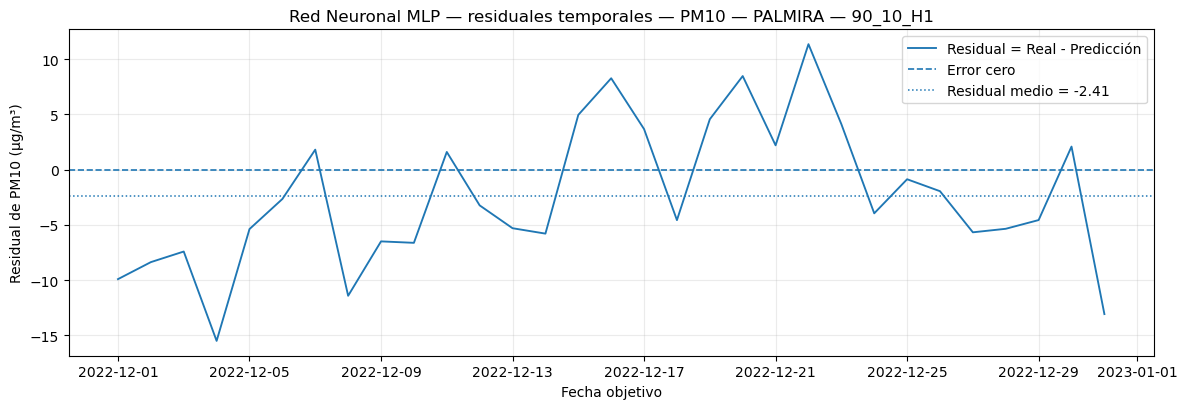

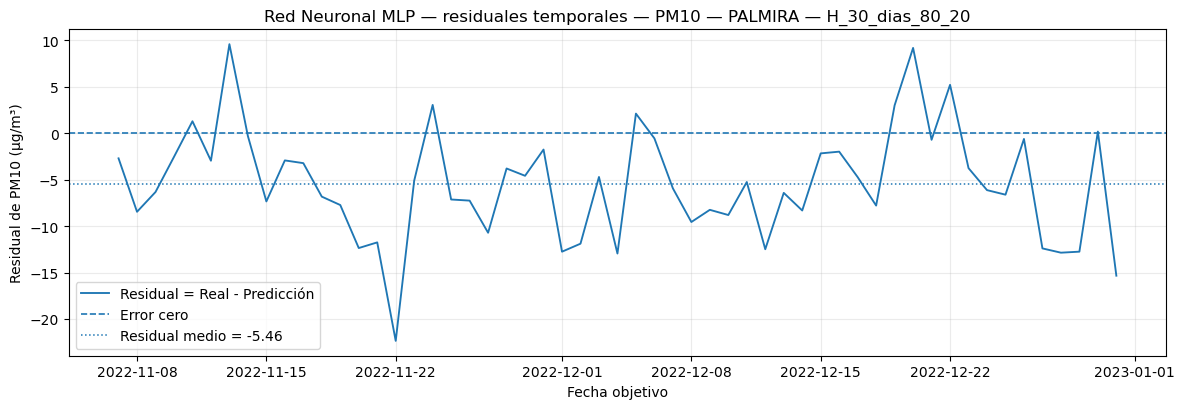

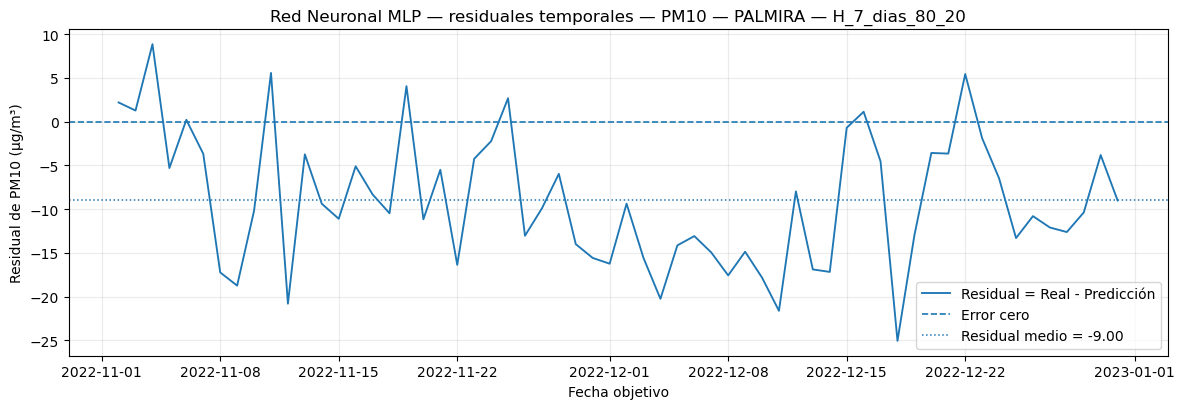

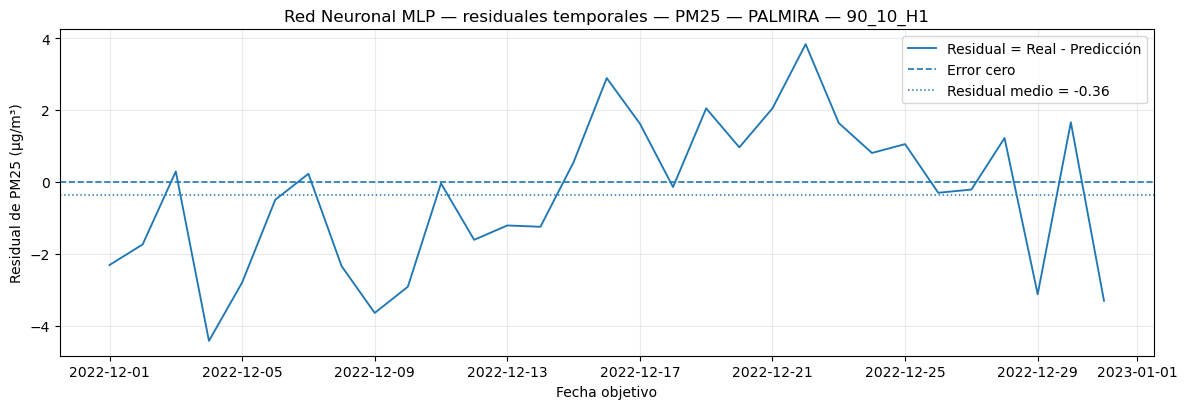

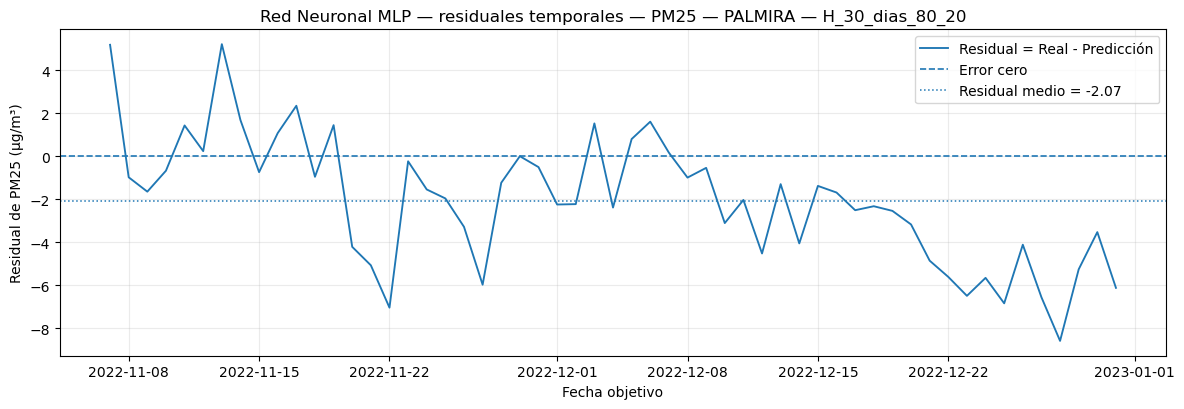

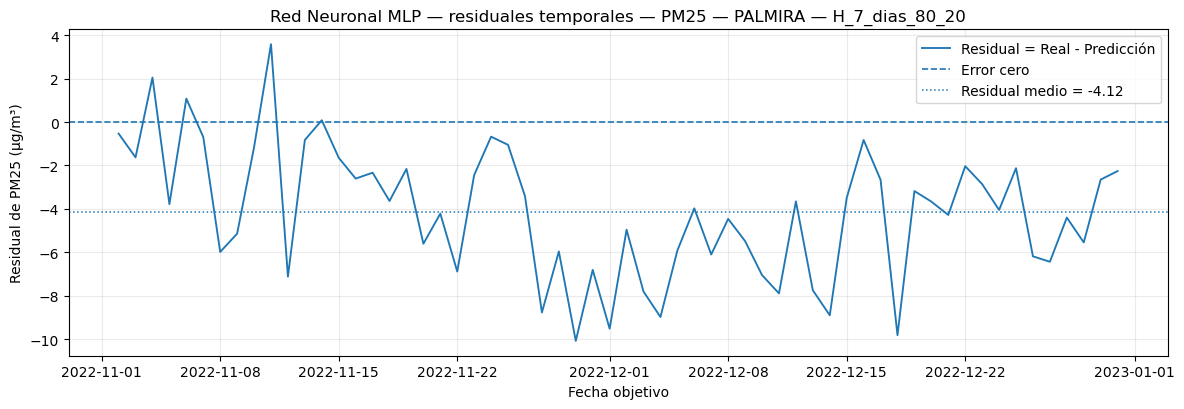

Resumen de residuales guardado en: C:\Users\santi\Prediccion_Cali_3_Version\salidas_MLP_TESIS_PROTOCOLO_TEMPORAL\tablas\MLP_resumen_residuales.csv
Gráficas residuales de todos los escenarios en: C:\Users\santi\Prediccion_Cali_3_Version\salidas_MLP_TESIS_PROTOCOLO_TEMPORAL\graficas\residuales_todos_escenarios


In [13]:
# ============================================================
# DIAGNÓSTICO TEMPORAL DE RESIDUALES: REAL - PREDICCIÓN
# ============================================================

if predicciones_mlp_df.empty:
    raise ValueError("No hay predicciones disponibles para calcular residuales.")

# Residual con convención explícita para la tesis: observado menos predicho.
predicciones_mlp_df = predicciones_mlp_df.copy()
predicciones_mlp_df["Residual"] = predicciones_mlp_df["Real"] - predicciones_mlp_df["Prediccion"]
predicciones_mlp_df["Error_absoluto"] = predicciones_mlp_df["Residual"].abs()
if "Persistencia" in predicciones_mlp_df.columns:
    predicciones_mlp_df["Residual_persistencia"] = predicciones_mlp_df["Real"] - predicciones_mlp_df["Persistencia"]

# Resumen de diagnóstico residual por escenario.
def _autocorr_lag1_residual(serie):
    serie = pd.Series(serie).dropna()
    return serie.autocorr(lag=1) if len(serie) >= 3 else np.nan

resumen_residuales_mlp = (
    predicciones_mlp_df
    .groupby(["Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias"], as_index=False)
    .agg(
        N_residuales=("Residual", "count"),
        Residual_medio=("Residual", "mean"),
        Residual_mediana=("Residual", "median"),
        Residual_desv_std=("Residual", "std"),
        MAE_desde_residual=("Error_absoluto", "mean"),
        P95_error_absoluto=("Error_absoluto", lambda x: x.quantile(0.95)),
        Max_error_absoluto=("Error_absoluto", "max"),
        Autocorr_residual_lag1=("Residual", _autocorr_lag1_residual),
    )
    .sort_values(["Variable", "Estacion", "Horizonte_dias", "Escenario"])
    .reset_index(drop=True)
)

display(Markdown("## Diagnóstico de residuales — Red Neuronal MLP"))
display(resumen_residuales_mlp.round(4))

# Carpeta específica: se guardan todos los escenarios aunque solo se muestren los mejores.
GRAFICAS_RESIDUALES_MLP = GRAFICAS_MLP / "residuales_todos_escenarios"
GRAFICAS_RESIDUALES_MLP.mkdir(parents=True, exist_ok=True)

# Identificar mejores escenarios para mostrarlos en pantalla sin saturar el notebook.
_mejores_claves_mlp = set(
    zip(mejor_mlp["Variable"], mejor_mlp["Estacion"], mejor_mlp["Escenario"])
)

for (variable, estacion, escenario, horizonte), sub in predicciones_mlp_df.groupby(
    ["Variable", "Estacion", "Escenario", "Horizonte_dias"]
):
    sub = sub.sort_values("Fecha_objetivo").copy()
    if sub.empty:
        continue

    media_residual = sub["Residual"].mean()

    plt.figure(figsize=(12, 4.2))
    plt.plot(sub["Fecha_objetivo"], sub["Residual"], linewidth=1.35, label="Residual = Real - Predicción")
    plt.axhline(0, linestyle="--", linewidth=1.2, label="Error cero")
    plt.axhline(media_residual, linestyle=":", linewidth=1.1, label=f"Residual medio = {media_residual:.2f}")
    plt.xlabel("Fecha objetivo")
    plt.ylabel(f"Residual de {variable} (µg/m³)")
    plt.title(f"Red Neuronal MLP — residuales temporales — {variable} — {estacion} — {escenario}")
    plt.legend(loc="best")
    plt.grid(alpha=0.25)
    plt.tight_layout()

    nombre = nombre_seguro_mlp(f"{variable}_{estacion}_{escenario}_H{horizonte}")
    plt.savefig(
        GRAFICAS_RESIDUALES_MLP / f"MLP_residual_{nombre}.png",
        dpi=180,
        bbox_inches="tight"
    )

    # Solo se muestra el mejor escenario por estación/variable; los demás quedan guardados.
    if (variable, estacion, escenario) in _mejores_claves_mlp:
        plt.show()
    plt.close()

# Tabla específica de residuales para trazabilidad.
ruta_residuales_mlp = TABLAS_MLP / "MLP_resumen_residuales.csv"
resumen_residuales_mlp.to_csv(ruta_residuales_mlp, index=False, encoding="utf-8-sig")
print("Resumen de residuales guardado en:", ruta_residuales_mlp.resolve())
print("Gráficas residuales de todos los escenarios en:", GRAFICAS_RESIDUALES_MLP.resolve())


## Figuras completas por intervalo: entrenamiento, predicción y residual

Para cada escenario se presenta una figura con dos paneles sincronizados en el tiempo:

1. **Panel superior:** serie observada usada como entrenamiento, serie observada de prueba y predicción del modelo. La línea vertical marca el inicio del conjunto de prueba. Cuando existe una purga temporal, se identifica visualmente entre el final del entrenamiento y el inicio de prueba.
2. **Panel inferior:** residual fuera de muestra, definido como \(e_t = y_t - \hat{y}_t\). Un residual positivo indica subestimación y uno negativo indica sobreestimación.

El residual se calcula sobre **prueba**, porque es donde se evalúa la capacidad predictiva fuera de muestra. No se desplaza la predicción para mejorar artificialmente su coincidencia visual.


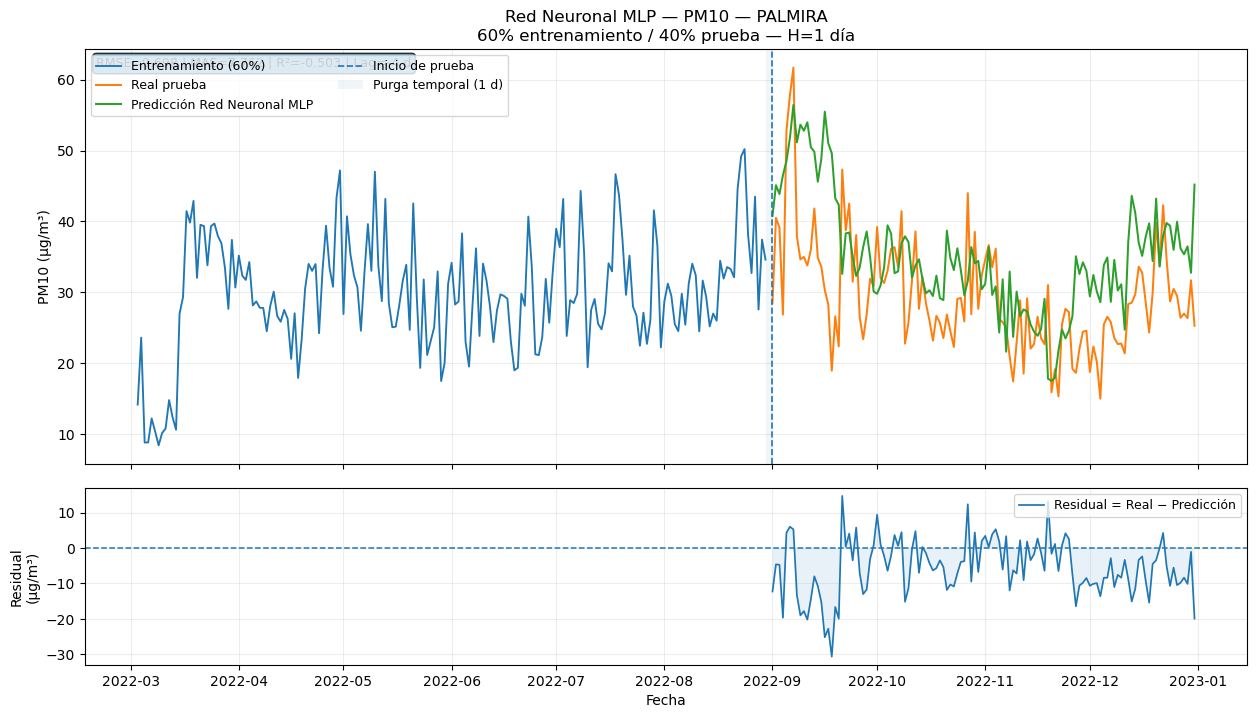

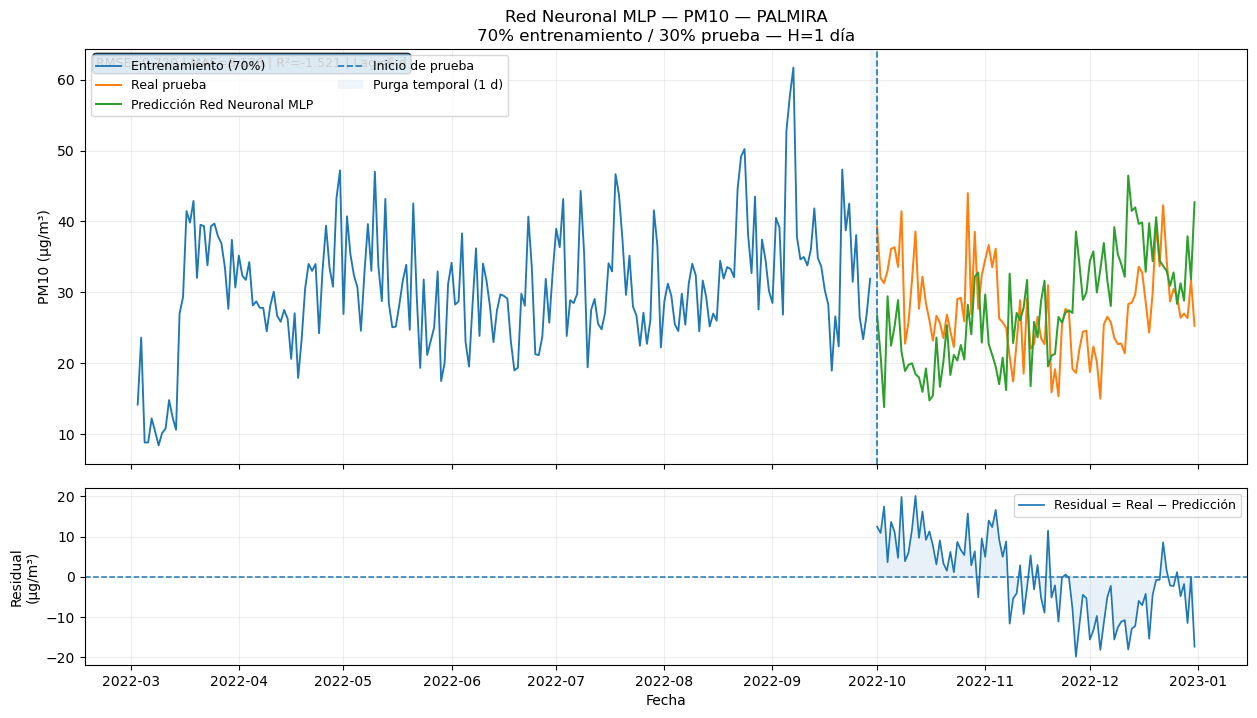

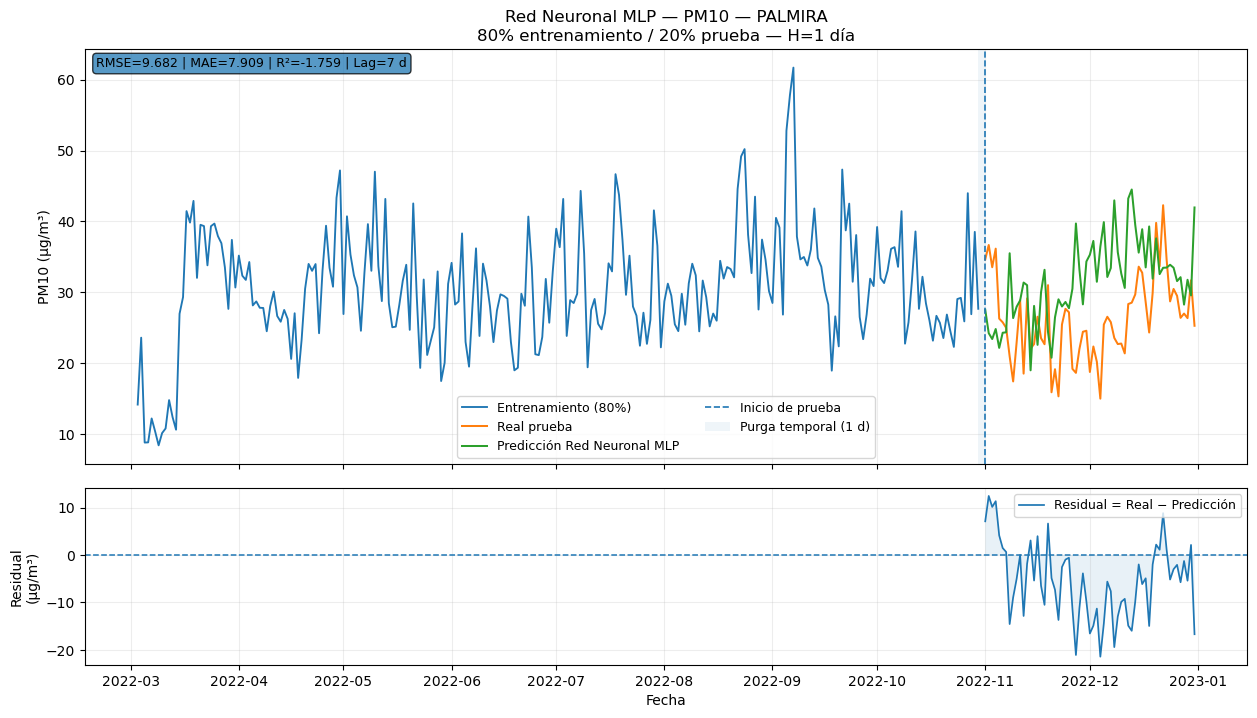

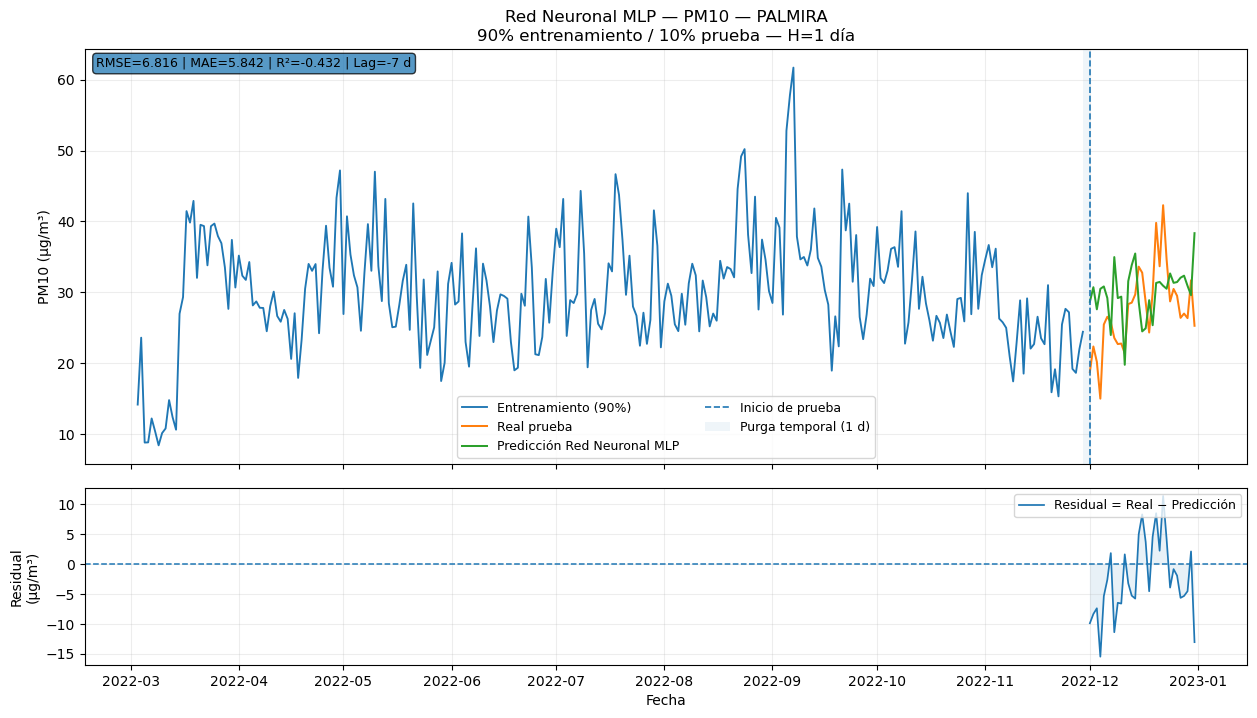

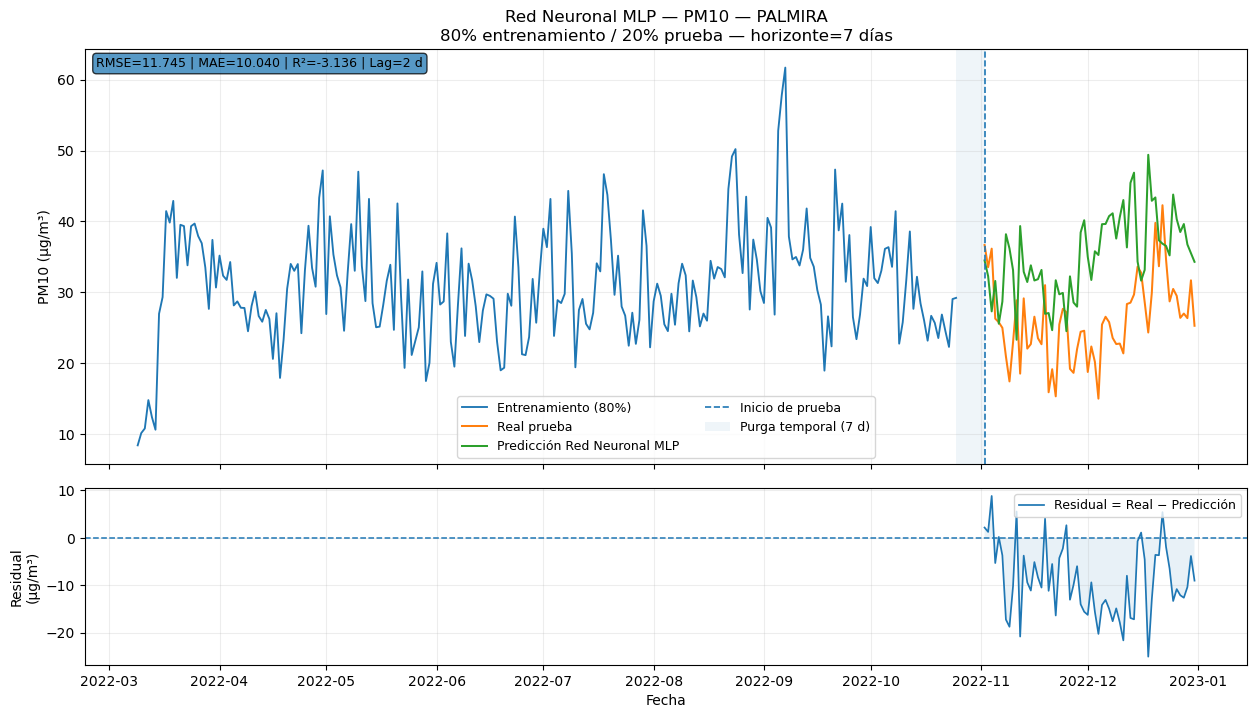

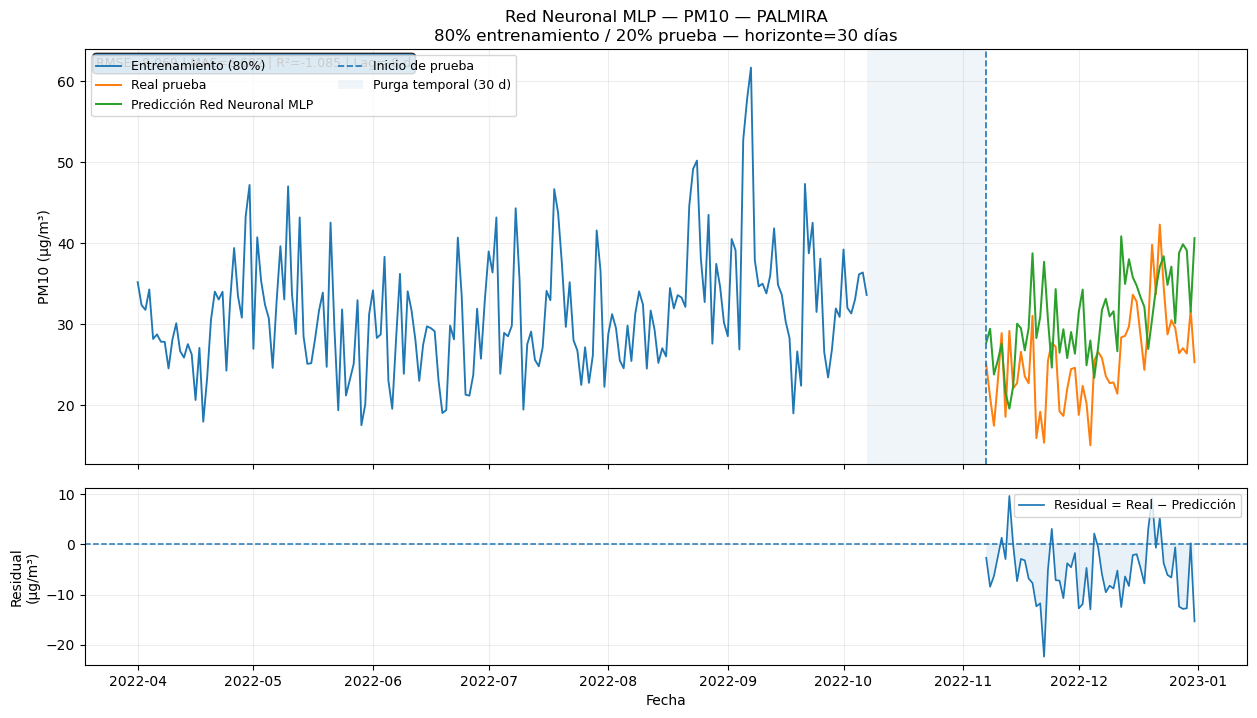

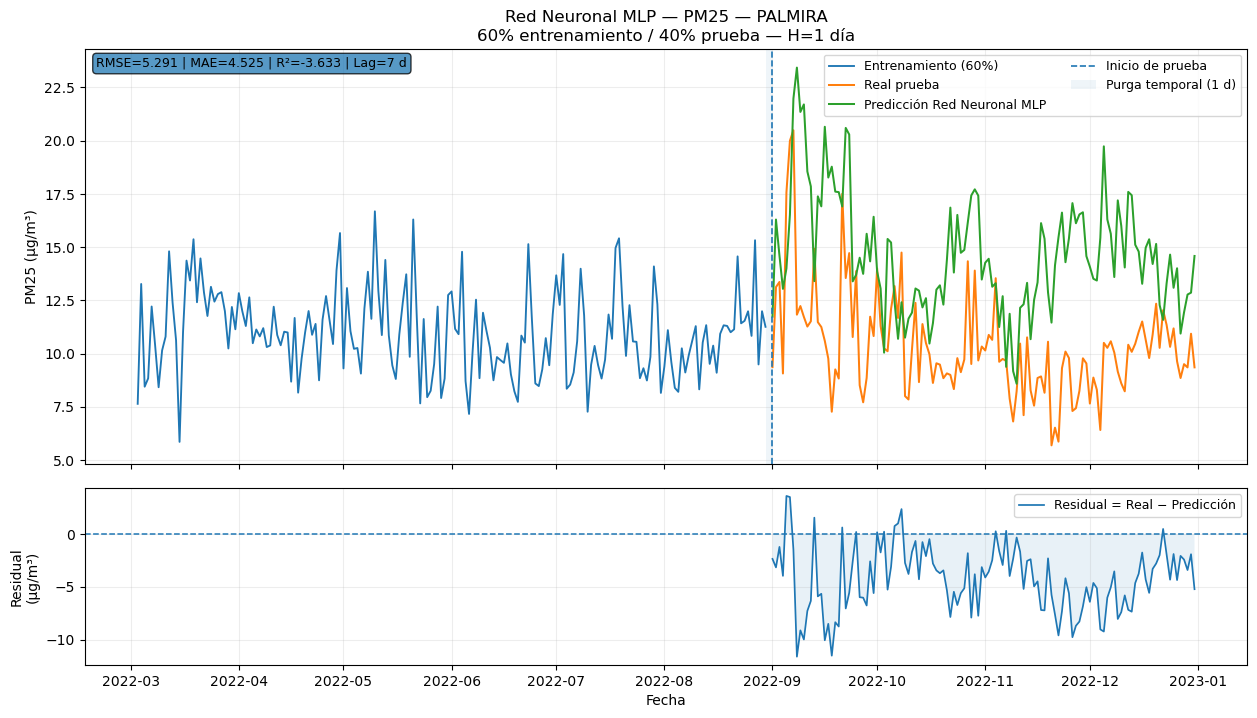

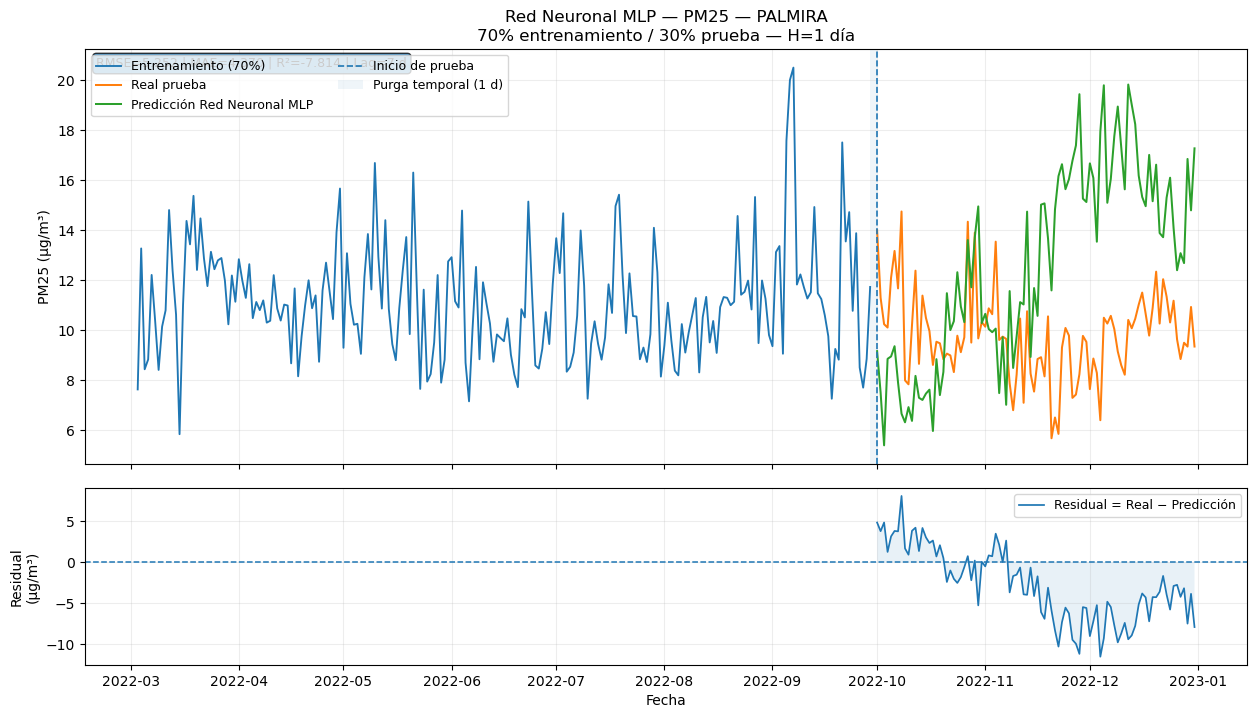

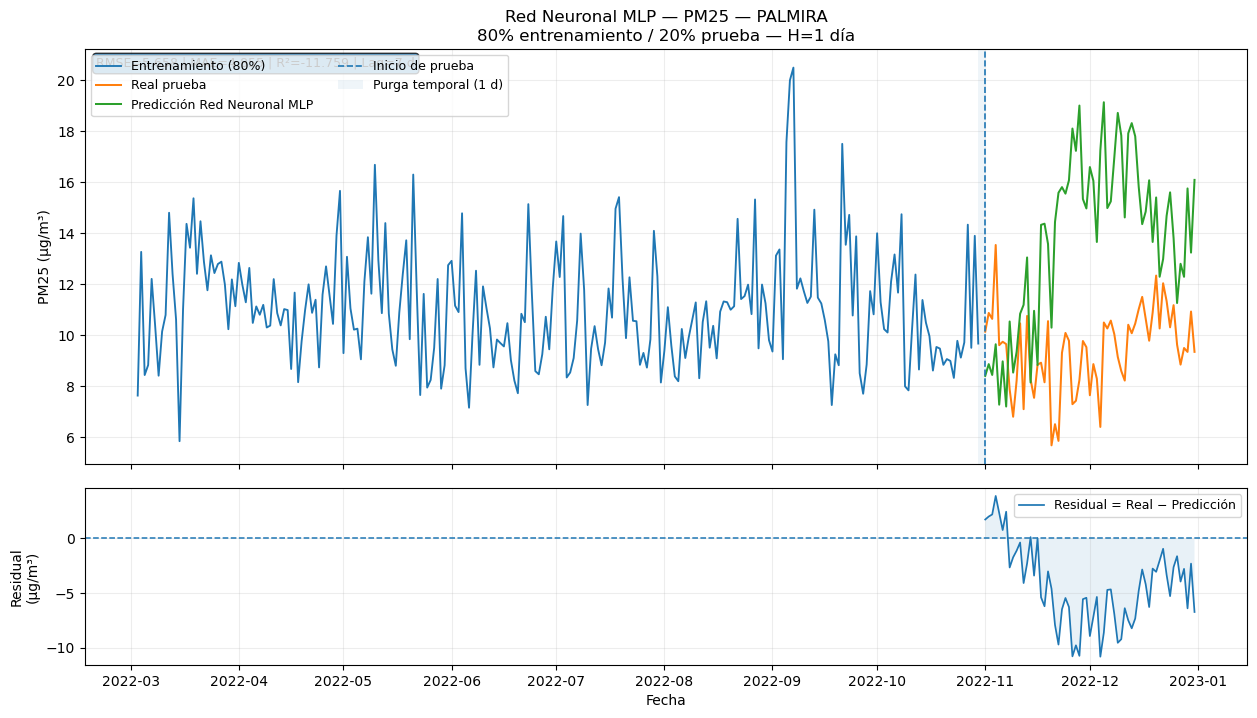

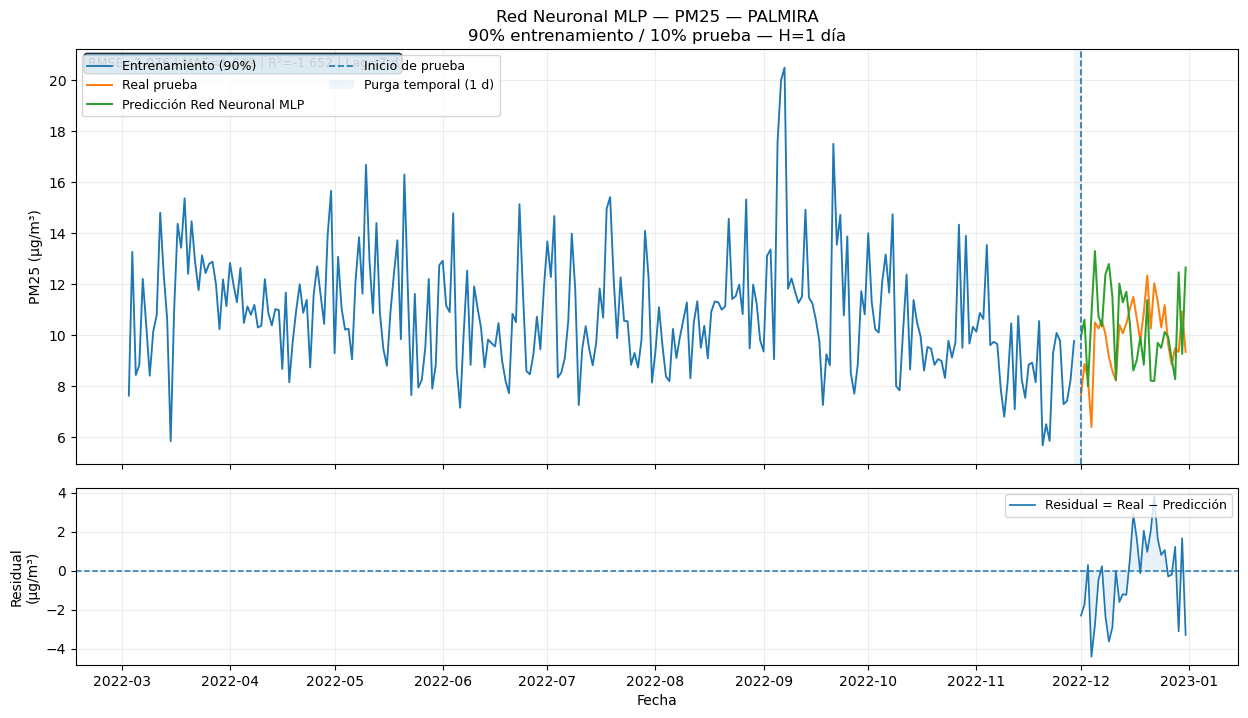

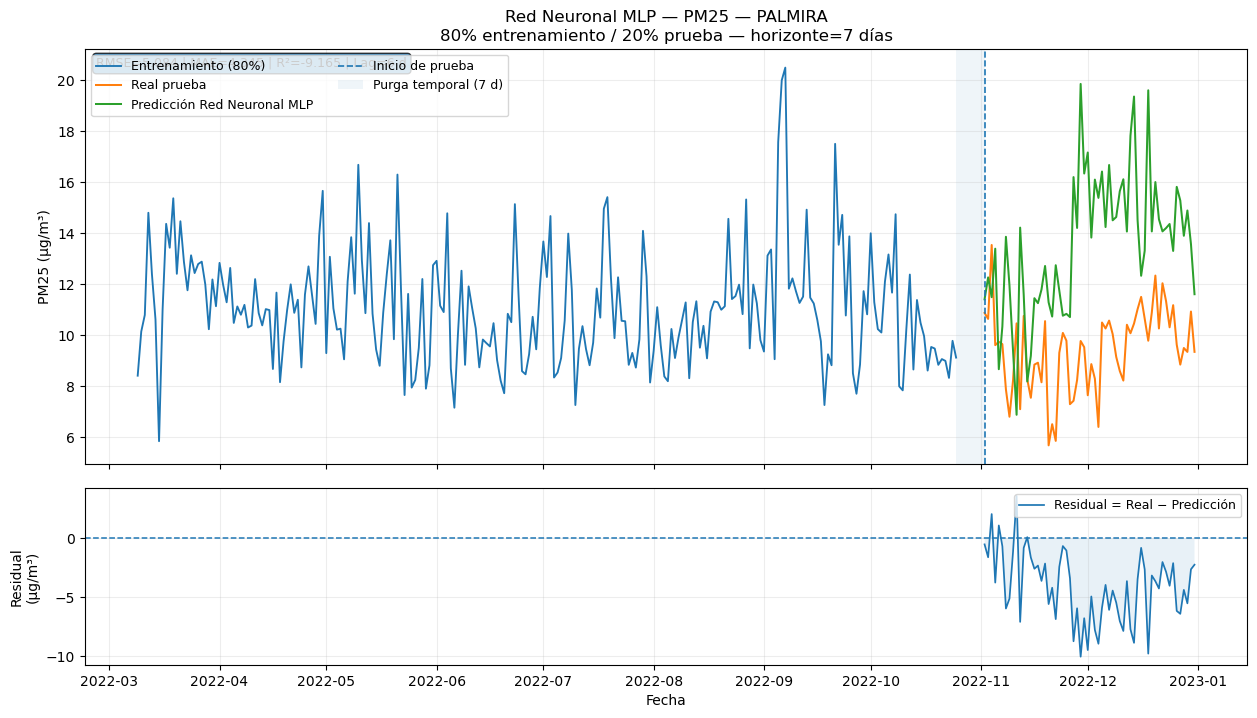

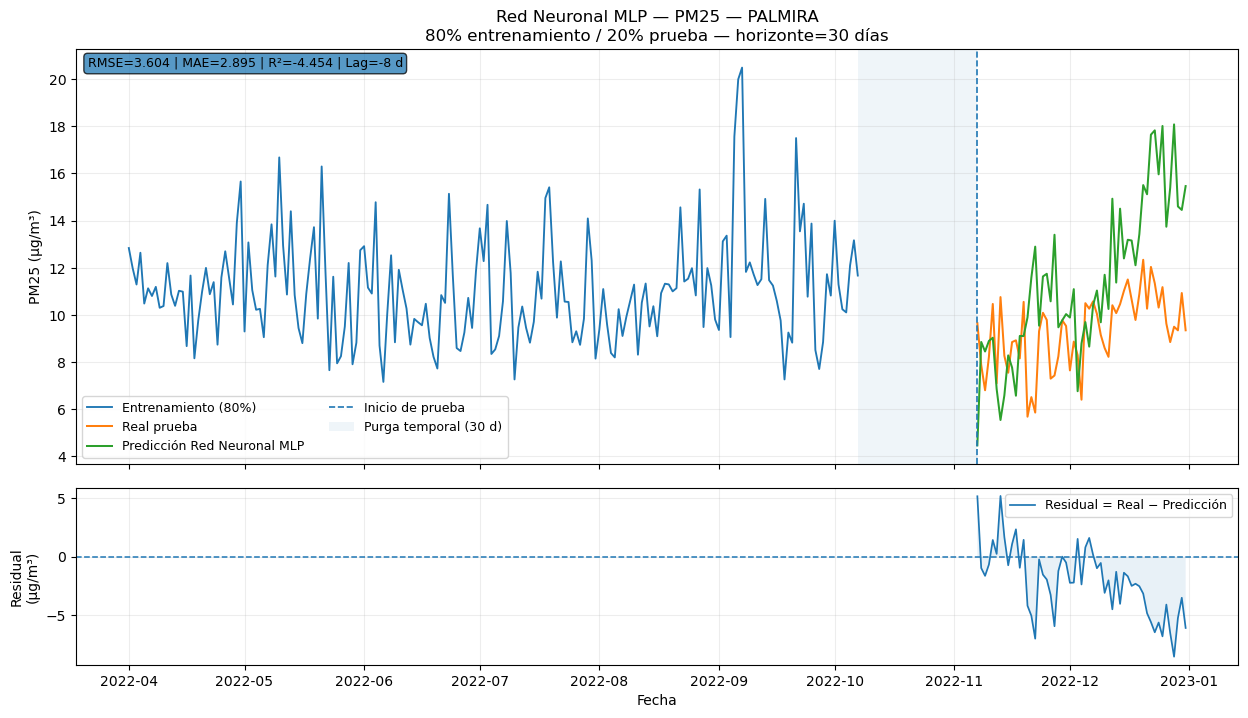

Figuras entrenamiento/prueba + residual generadas: 12


In [14]:
# V3_GRAFICAS_TRAIN_TEST_RESIDUAL
# ============================================================
# FIGURAS POR CADA INTERVALO: ENTRENAMIENTO + PRUEBA/PREDICCIÓN
# Y RESIDUAL (REAL - PREDICCIÓN) EN PANEL INFERIOR
# ============================================================

# Asegurar tipos temporales y residual.
predicciones_mlp_df = predicciones_mlp_df.copy()
predicciones_mlp_df["Fecha_objetivo"] = pd.to_datetime(predicciones_mlp_df["Fecha_objetivo"], errors="coerce")
predicciones_mlp_df["Residual"] = predicciones_mlp_df["Real"] - predicciones_mlp_df["Prediccion"]

_base_graf_mlp = base_mlp.copy()
_base_graf_mlp["Fecha inicial"] = pd.to_datetime(_base_graf_mlp["Fecha inicial"], errors="coerce")


def _etiqueta_intervalo_mlp(tipo, train_nominal, horizonte):
    train_nominal = float(train_nominal)
    test_nominal = 100.0 - train_nominal
    if str(tipo).lower().startswith("particion"):
        return f"{train_nominal:.0f}% entrenamiento / {test_nominal:.0f}% prueba — H=1 día"
    return f"{train_nominal:.0f}% entrenamiento / {test_nominal:.0f}% prueba — horizonte={int(horizonte)} días"


def _graficar_intervalo_mlp(fila_cfg):
    variable = fila_cfg["Variable"]
    estacion = fila_cfg["Estacion"]
    escenario = fila_cfg["Escenario"]
    tipo_eval = fila_cfg["Tipo_evaluacion"]
    horizonte = int(fila_cfg["Horizonte_dias"])

    sub = predicciones_mlp_df[
        (predicciones_mlp_df["Variable"] == variable) &
        (predicciones_mlp_df["Estacion"] == estacion) &
        (predicciones_mlp_df["Escenario"] == escenario)
    ].sort_values("Fecha_objetivo").copy()
    if sub.empty:
        return

    # Configuración temporal registrada para este escenario.
    trow = tiempos_mlp_df[
        (tiempos_mlp_df["Variable"] == variable) &
        (tiempos_mlp_df["Estacion"] == estacion) &
        (tiempos_mlp_df["Escenario"] == escenario)
    ]
    if trow.empty:
        train_nominal = 80.0
        gap_dias = horizonte
    else:
        train_nominal = float(trow.iloc[0]["Train_nominal_%"])
        gap_dias = int(trow.iloc[0].get("Gap_purga_dias", horizonte))

    # Fechas exactas del tramo de entrenamiento utilizadas por el protocolo.
    train_info = metricas_mlp_df[
        (metricas_mlp_df["Variable"] == variable) &
        (metricas_mlp_df["Estacion"] == estacion) &
        (metricas_mlp_df["Escenario"] == escenario) &
        (metricas_mlp_df["Etapa"] == "Entrenamiento")
    ]

    fecha_test_inicio = pd.to_datetime(sub["Fecha_objetivo"].min())
    if not train_info.empty:
        fecha_train_inicio = pd.to_datetime(train_info.iloc[0]["Fecha_inicio"])
        fecha_train_fin = pd.to_datetime(train_info.iloc[0]["Fecha_fin"])
    else:
        fecha_train_inicio = pd.to_datetime(_base_graf_mlp["Fecha inicial"].min())
        fecha_train_fin = fecha_test_inicio - pd.Timedelta(days=max(1, gap_dias))

    serie = _base_graf_mlp[
        (_base_graf_mlp["Estacion"] == estacion)
    ][["Fecha inicial", variable]].copy()
    serie[variable] = pd.to_numeric(serie[variable], errors="coerce")
    serie = serie.dropna(subset=["Fecha inicial", variable]).sort_values("Fecha inicial")

    train_obs = serie[
        (serie["Fecha inicial"] >= fecha_train_inicio) &
        (serie["Fecha inicial"] <= fecha_train_fin)
    ].copy()

    residual = sub["Residual"].astype(float)
    rmse = float(np.sqrt(np.nanmean(np.square(residual)))) if residual.notna().any() else np.nan
    mae = float(np.nanmean(np.abs(residual))) if residual.notna().any() else np.nan
    r2_row = metricas_mlp_df[
        (metricas_mlp_df["Variable"] == variable) &
        (metricas_mlp_df["Estacion"] == estacion) &
        (metricas_mlp_df["Escenario"] == escenario) &
        (metricas_mlp_df["Etapa"] == "Prueba")
    ]
    r2 = float(r2_row.iloc[0]["R2"]) if (not r2_row.empty and "R2" in r2_row.columns) else np.nan
    lag = float(r2_row.iloc[0]["Lag_optimo_dias"]) if (not r2_row.empty and "Lag_optimo_dias" in r2_row.columns) else np.nan

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(15, 8), sharex=True,
        gridspec_kw={"height_ratios": [2.35, 1.0], "hspace": 0.08}
    )

    # Panel superior: mismo concepto visual de la figura solicitada.
    ax1.plot(train_obs["Fecha inicial"], train_obs[variable],
             label=f"Entrenamiento ({train_nominal:.0f}%)", linewidth=1.35)
    ax1.plot(sub["Fecha_objetivo"], sub["Real"],
             label="Real prueba", linewidth=1.45)
    ax1.plot(sub["Fecha_objetivo"], sub["Prediccion"],
             label="Predicción Red Neuronal MLP", linewidth=1.45)
    ax1.axvline(fecha_test_inicio, linestyle="--", linewidth=1.2, label="Inicio de prueba")

    # Mostrar la purga temporal sin confundirla con datos de prueba.
    if pd.notna(fecha_train_fin) and fecha_train_fin < fecha_test_inicio:
        ax1.axvspan(fecha_train_fin, fecha_test_inicio, alpha=0.07,
                    label=f"Purga temporal ({gap_dias} d)")

    etiqueta = _etiqueta_intervalo_mlp(tipo_eval, train_nominal, horizonte)
    ax1.set_title(f"Red Neuronal MLP — {variable} — {estacion}\n{etiqueta}")
    ax1.set_ylabel(f"{variable} (µg/m³)")
    ax1.grid(alpha=0.22)
    ax1.legend(ncol=2, fontsize=9)

    texto_metricas = f"RMSE={rmse:.3f} | MAE={mae:.3f} | R²={r2:.3f}"
    if np.isfinite(lag):
        texto_metricas += f" | Lag={lag:.0f} d"
    ax1.text(0.01, 0.98, texto_metricas, transform=ax1.transAxes,
             va="top", ha="left", fontsize=9,
             bbox=dict(boxstyle="round,pad=0.3", alpha=0.75))

    # Panel inferior: resta Real - Predicción para las mismas fechas de prueba.
    ax2.plot(sub["Fecha_objetivo"], residual, linewidth=1.25, label="Residual = Real − Predicción")
    ax2.axhline(0, linestyle="--", linewidth=1.1)
    ax2.fill_between(sub["Fecha_objetivo"], residual, 0, alpha=0.10)
    ax2.set_ylabel("Residual\n(µg/m³)")
    ax2.set_xlabel("Fecha")
    ax2.grid(alpha=0.22)
    ax2.legend(loc="upper right", fontsize=9)

    fig.tight_layout()
    nombre = nombre_seguro_mlp(f"{variable}_{estacion}_{escenario}")
    ruta = GRAFICAS_MLP / f"MLP_train_test_residual_{nombre}.png"
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# Se muestran y guardan TODOS los escenarios: 60/40, 70/30, 80/20, 90/10, H7, H30 y H90.
_cfg_graficas_mlp = (
    predicciones_mlp_df[["Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias"]]
    .drop_duplicates()
    .merge(
        tiempos_mlp_df[["Variable", "Estacion", "Escenario", "Orden_escenario"]].drop_duplicates(),
        on=["Variable", "Estacion", "Escenario"], how="left"
    )
    .sort_values(["Variable", "Estacion", "Orden_escenario", "Horizonte_dias"])
)

for _, _fila_cfg in _cfg_graficas_mlp.iterrows():
    _graficar_intervalo_mlp(_fila_cfg)

print(f"Figuras entrenamiento/prueba + residual generadas: {len(_cfg_graficas_mlp)}")


## Tiempo de ejecución por intervalo de predicción

El tiempo total del notebook se conserva como referencia global, pero la tabla principal de costo computacional se desagrega por escenario. Para cada intervalo se acumulan los tiempos de validación temporal, entrenamiento final y predicción de todas las estaciones/contaminantes procesados en ese escenario. También se conserva el detalle por configuración con sus hiperparámetros seleccionados.


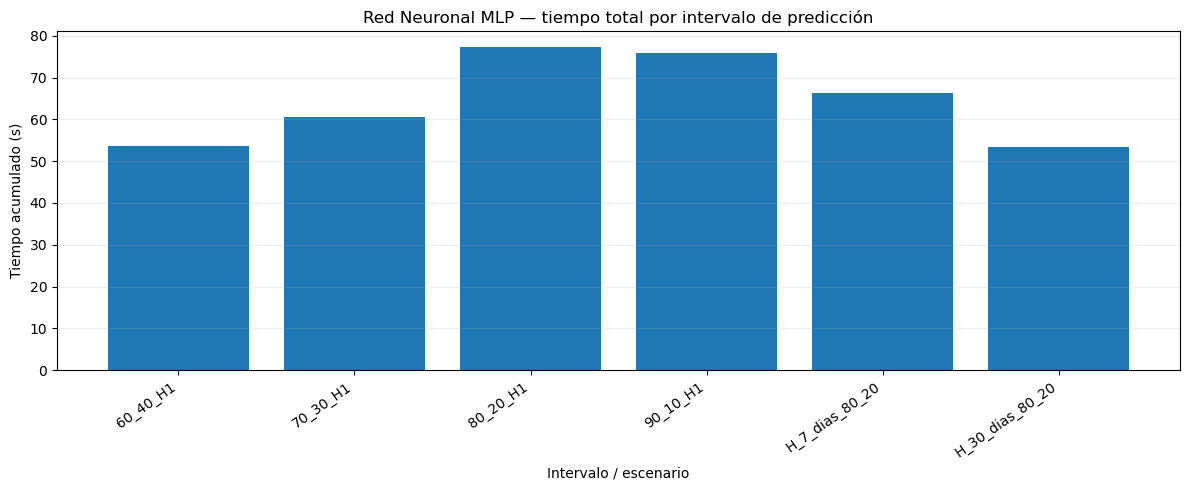

### Tiempo de código por partición porcentual

,Orden_escenario,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,N_configuraciones,Tiempo_CV_acumulado_s,Tiempo_entrenamiento_acumulado_s,Tiempo_prediccion_acumulado_s,Tiempo_total_intervalo_s,Tiempo_promedio_configuracion_s,Tiempo_total_intervalo_min
0,1,Particion porcentual,60_40_H1,1,60.0,40.0,2,49.3429,3.8895,0.0140,53.6323,26.8161,0.8939
1,2,Particion porcentual,70_30_H1,1,70.0,30.0,2,54.7718,5.4193,0.0127,60.5192,30.2596,1.0087
2,3,Particion porcentual,80_20_H1,1,80.0,20.0,2,72.1228,4.7447,0.0106,77.1893,38.5946,1.2865
3,4,Particion porcentual,90_10_H1,1,90.0,10.0,2,69.5455,5.9609,0.0137,75.7847,37.8923,1.2631


### Tiempo de código por horizonte fijo

,Orden_escenario,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,N_configuraciones,Tiempo_CV_acumulado_s,Tiempo_entrenamiento_acumulado_s,Tiempo_prediccion_acumulado_s,Tiempo_total_intervalo_s,Tiempo_promedio_configuracion_s,Tiempo_total_intervalo_min
4,5,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,2,59.5465,6.5159,0.0141,66.3901,33.1951,1.1065
5,6,Horizonte fijo,H_30_dias_80_20,30,80.0,20.0,2,48.7733,4.2202,0.0159,53.3906,26.6953,0.8898


### Configuración e hiperparámetros por intervalo

,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,Hiperparametros_seleccionados,Tiempo_total_escenario_s,Tiempo_total_escenario_min,RMSE_CV_mejor,R2_CV_mejor,Lag_abs_CV_mejor,Score_CV_alineado
0,PM10,PALMIRA,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.001, ""early_...",33.355999,0.555933,8.734198,-0.782405,3.0,0.348675
1,PM25,PALMIRA,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",20.276294,0.337938,16.232935,-174.359882,2.8,0.000000
2,PM10,PALMIRA,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",38.223395,0.637057,9.008846,-0.548370,2.8,0.133333
3,PM25,PALMIRA,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",22.295765,0.371596,17.290874,-194.299331,2.8,0.000000
4,PM10,PALMIRA,Particion porcentual,80_20_H1,1,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",46.181146,0.769686,10.027590,-1.297553,3.2,0.000000
5,PM25,PALMIRA,Particion porcentual,80_20_H1,1,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",31.008121,0.516802,20.889046,-293.972997,3.6,0.000000
6,PM10,PALMIRA,Particion porcentual,90_10_H1,1,90.0,10.0,"{""activation"": ""relu"", ""alpha"": 0.001, ""early_...",47.866242,0.797771,9.399208,-0.782318,2.8,0.000000
7,PM25,PALMIRA,Particion porcentual,90_10_H1,1,90.0,10.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",27.918428,0.465307,20.586586,-304.532062,3.6,0.000000
8,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.001, ""early_...",42.410219,0.706837,9.728118,-1.047361,4.8,0.020000
9,PM25,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",23.979898,0.399665,23.232005,-451.136560,5.6,0.166667


In [15]:
# V3_TIEMPOS_POR_INTERVALO
# ============================================================
# TIEMPOS POR INTERVALO / ESCENARIO + CONFIGURACIÓN E HIPERPARÁMETROS
# ============================================================

_detalle_tiempos_mlp = tiempos_mlp_df.copy()
_detalle_tiempos_mlp["Test_nominal_%"] = 100.0 - _detalle_tiempos_mlp["Train_nominal_%"].astype(float)

columnas_detalle_mlp = [
    "Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Orden_escenario",
    "Horizonte_dias", "Train_nominal_%", "Test_nominal_%", "Train_efectivo_%", "Test_efectivo_%",
    "Gap_purga_dias", "N_train", "N_test", "N_features",
    "Tiempo_validacion_CV_s", "Tiempo_entrenamiento_final_s", "Tiempo_prediccion_s",
    "Tiempo_total_escenario_s", "Tiempo_total_escenario_min",
    "Hiperparametros_seleccionados"
]
# Algunas columnas específicas del modelo pueden agregarse si existen.
for _c in ["Tipo_modelo_RF", "RMSE_CV_mejor", "R2_CV_mejor", "Lag_abs_CV_mejor", "Score_CV_alineado"]:
    if _c in _detalle_tiempos_mlp.columns and _c not in columnas_detalle_mlp:
        columnas_detalle_mlp.append(_c)
columnas_detalle_mlp = [_c for _c in columnas_detalle_mlp if _c in _detalle_tiempos_mlp.columns]

detalle_tiempos_intervalos_mlp_df = (
    _detalle_tiempos_mlp[columnas_detalle_mlp]
    .sort_values(["Orden_escenario", "Variable", "Estacion"])
    .reset_index(drop=True)
)

resumen_tiempos_intervalos_mlp_df = (
    _detalle_tiempos_mlp
    .groupby([
        "Orden_escenario", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
        "Train_nominal_%", "Test_nominal_%"
    ], as_index=False)
    .agg(
        N_configuraciones=("Escenario", "size"),
        Tiempo_CV_acumulado_s=("Tiempo_validacion_CV_s", "sum"),
        Tiempo_entrenamiento_acumulado_s=("Tiempo_entrenamiento_final_s", "sum"),
        Tiempo_prediccion_acumulado_s=("Tiempo_prediccion_s", "sum"),
        Tiempo_total_intervalo_s=("Tiempo_total_escenario_s", "sum"),
        Tiempo_promedio_configuracion_s=("Tiempo_total_escenario_s", "mean"),
    )
    .sort_values("Orden_escenario")
    .reset_index(drop=True)
)
resumen_tiempos_intervalos_mlp_df["Tiempo_total_intervalo_min"] = resumen_tiempos_intervalos_mlp_df["Tiempo_total_intervalo_s"] / 60.0

# Tabla específica solicitada para 60/40, 70/30, 80/20 y 90/10.
tiempos_particiones_mlp_df = resumen_tiempos_intervalos_mlp_df[
    resumen_tiempos_intervalos_mlp_df["Tipo_evaluacion"] == "Particion porcentual"
].copy()

# Tabla específica para horizontes fijos de 7, 30 y 90 días.
tiempos_horizontes_mlp_df = resumen_tiempos_intervalos_mlp_df[
    resumen_tiempos_intervalos_mlp_df["Tipo_evaluacion"] == "Horizonte fijo"
].copy()

# Hiperparámetros efectivamente seleccionados en cada intervalo, por estación/variable.
configuracion_por_intervalo_mlp_df = detalle_tiempos_intervalos_mlp_df[[
    _c for _c in [
        "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
        "Train_nominal_%", "Test_nominal_%", "Hiperparametros_seleccionados",
        "Tiempo_total_escenario_s", "Tiempo_total_escenario_min",
        "RMSE_CV_mejor", "R2_CV_mejor", "Lag_abs_CV_mejor", "Score_CV_alineado",
        "Tipo_modelo_RF"
    ] if _c in detalle_tiempos_intervalos_mlp_df.columns
]].copy()

# Exportaciones CSV independientes, listas para compartir y auditar.
ruta_resumen_tiempos_mlp = TABLAS_MLP / "MLP_TIEMPOS_POR_INTERVALO.csv"
ruta_detalle_tiempos_mlp = TABLAS_MLP / "MLP_DETALLE_TIEMPOS_CONFIGURACION_POR_INTERVALO.csv"
ruta_config_intervalo_mlp = TABLAS_MLP / "MLP_CONFIGURACION_HIPERPARAMETROS_POR_INTERVALO.csv"

resumen_tiempos_intervalos_mlp_df.to_csv(ruta_resumen_tiempos_mlp, index=False, encoding="utf-8-sig")
detalle_tiempos_intervalos_mlp_df.to_csv(ruta_detalle_tiempos_mlp, index=False, encoding="utf-8-sig")
configuracion_por_intervalo_mlp_df.to_csv(ruta_config_intervalo_mlp, index=False, encoding="utf-8-sig")

# Figura concisa del costo computacional por intervalo.
plt.figure(figsize=(12, 5))
plt.bar(resumen_tiempos_intervalos_mlp_df["Escenario"], resumen_tiempos_intervalos_mlp_df["Tiempo_total_intervalo_s"])
plt.xticks(rotation=35, ha="right")
plt.ylabel("Tiempo acumulado (s)")
plt.xlabel("Intervalo / escenario")
plt.title("Red Neuronal MLP — tiempo total por intervalo de predicción")
plt.grid(axis="y", alpha=0.22)
plt.tight_layout()
plt.savefig(GRAFICAS_MLP / "MLP_tiempo_total_por_intervalo.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# Estas son las tablas que deben aparecer al final del notebook.
display(Markdown("### Tiempo de código por partición porcentual"))
display(tiempos_particiones_mlp_df.round(4))
display(Markdown("### Tiempo de código por horizonte fijo"))
display(tiempos_horizontes_mlp_df.round(4))
display(Markdown("### Configuración e hiperparámetros por intervalo"))
display(configuracion_por_intervalo_mlp_df)


In [16]:

# ============================================================
# 13. EXPORTACIÓN, TRAZABILIDAD Y TIEMPO TOTAL
# ============================================================

hiperparametros_seleccionados_mlp = tiempos_mlp_df[[
    "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
    "Hiperparametros_seleccionados"
]].drop_duplicates().sort_values(["Variable", "Estacion", "Horizonte_dias"])

archivos_mlp = {
    "metricas_tesis": TABLAS_MLP / "MLP_metricas_prueba_tesis.csv",
    "metricas_maestro": TABLAS_MLP / "MLP_METRICAS_MAESTRO_COMPARACION.csv",
    "tiempos_tesis": TABLAS_MLP / "MLP_tiempos_configuracion_hiperparametros.csv",
    "predicciones": TABLAS_MLP / "MLP_predicciones_prueba.csv",
    "cv_resumen": TABLAS_MLP / "MLP_validacion_temporal_resumen.csv",
    "cv_folds": TABLAS_MLP / "MLP_validacion_temporal_folds.csv",
    "importancias": TABLAS_MLP / "MLP_importancia_permutacion_mejores.csv",
    "mejores": TABLAS_MLP / "MLP_mejor_escenario_por_estacion.csv",
    "escenarios": TABLAS_MLP / "MLP_escenarios.csv",
    "hiperparametros_candidatos": TABLAS_MLP / "MLP_hiperparametros_candidatos.csv",
    "hiperparametros_seleccionados": TABLAS_MLP / "MLP_hiperparametros_seleccionados.csv",
    "auditoria": TABLAS_MLP / "MLP_auditoria_supervisado.csv",
    "versiones": TABLAS_MLP / "MLP_versiones_entorno.csv",
    "residuales_resumen": TABLAS_MLP / "MLP_resumen_residuales.csv",
}

# CSV maestro: una fila por escenario con métricas + tiempos + configuración + alineación.
claves_maestro_mlp = ["Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias"]
metricas_maestro_mlp = metricas_prueba_mlp_df.merge(
    tiempos_mlp_df,
    on=claves_maestro_mlp,
    how="left",
    suffixes=("", "_tiempo")
)
metricas_maestro_mlp["Es_mejor_observado_por_horizonte"] = False
claves_mejor_mlp = set(zip(
    mejor_mlp["Variable"], mejor_mlp["Estacion"],
    mejor_mlp["Horizonte_dias"], mejor_mlp["Escenario"]
))
metricas_maestro_mlp["Es_mejor_observado_por_horizonte"] = [
    (v, e, h, esc) in claves_mejor_mlp
    for v, e, h, esc in zip(
        metricas_maestro_mlp["Variable"], metricas_maestro_mlp["Estacion"],
        metricas_maestro_mlp["Horizonte_dias"], metricas_maestro_mlp["Escenario"]
    )
]

tabla_metricas_tesis_mlp.to_csv(archivos_mlp["metricas_tesis"], index=False, encoding="utf-8-sig")
metricas_maestro_mlp.to_csv(archivos_mlp["metricas_maestro"], index=False, encoding="utf-8-sig")
tabla_tiempos_tesis_mlp.to_csv(archivos_mlp["tiempos_tesis"], index=False, encoding="utf-8-sig")
predicciones_mlp_df.to_csv(archivos_mlp["predicciones"], index=False, encoding="utf-8-sig")
cv_resumen_mlp_df.to_csv(archivos_mlp["cv_resumen"], index=False, encoding="utf-8-sig")
cv_folds_mlp_df.to_csv(archivos_mlp["cv_folds"], index=False, encoding="utf-8-sig")
importancias_mlp_df.to_csv(archivos_mlp["importancias"], index=False, encoding="utf-8-sig")
mejor_mlp.to_csv(archivos_mlp["mejores"], index=False, encoding="utf-8-sig")
escenarios_mlp_df.to_csv(archivos_mlp["escenarios"], index=False, encoding="utf-8-sig")
hiperparametros_mlp_df.to_csv(archivos_mlp["hiperparametros_candidatos"], index=False, encoding="utf-8-sig")
hiperparametros_seleccionados_mlp.to_csv(archivos_mlp["hiperparametros_seleccionados"], index=False, encoding="utf-8-sig")
auditoria_mlp_df.to_csv(archivos_mlp["auditoria"], index=False, encoding="utf-8-sig")
versiones_mlp_df.to_csv(archivos_mlp["versiones"], index=False, encoding="utf-8-sig")
resumen_residuales_mlp.to_csv(archivos_mlp["residuales_resumen"], index=False, encoding="utf-8-sig")

ruta_excel_mlp = SALIDAS_MLP / "MLP_RESUMEN_TESIS.xlsx"
with pd.ExcelWriter(ruta_excel_mlp, engine="openpyxl") as writer:
    metricas_maestro_mlp.to_excel(writer, sheet_name="metricas_maestro", index=False)
    tabla_metricas_tesis_mlp.to_excel(writer, sheet_name="metricas_prueba", index=False)
    tabla_tiempos_tesis_mlp.to_excel(writer, sheet_name="tiempos_config", index=False)
    mejor_mlp.to_excel(writer, sheet_name="mejores", index=False)
    resumen_escenarios_mlp.to_excel(writer, sheet_name="resumen_escenarios", index=False)
    hiperparametros_mlp_df.to_excel(writer, sheet_name="hp_candidatos", index=False)
    hiperparametros_seleccionados_mlp.to_excel(writer, sheet_name="hp_seleccionados", index=False)
    cv_resumen_mlp_df.to_excel(writer, sheet_name="cv_resumen", index=False)
    auditoria_mlp_df.to_excel(writer, sheet_name="auditoria", index=False)
    importancias_mlp_df.to_excel(writer, sheet_name="importancia_perm", index=False)
    versiones_mlp_df.to_excel(writer, sheet_name="versiones", index=False)
    resumen_residuales_mlp.to_excel(writer, sheet_name="residuales", index=False)
    tiempos_particiones_mlp_df.to_excel(writer, sheet_name="tiempos_particiones", index=False)
    tiempos_horizontes_mlp_df.to_excel(writer, sheet_name="tiempos_horizontes", index=False)
    configuracion_por_intervalo_mlp_df.to_excel(writer, sheet_name="config_por_intervalo", index=False)

TIEMPO_FIN_NOTEBOOK = time.perf_counter()
FECHA_HORA_FIN_NOTEBOOK = datetime.now()
TIEMPO_TOTAL_SEGUNDOS = TIEMPO_FIN_NOTEBOOK - TIEMPO_INICIO_NOTEBOOK

tiempo_notebook_mlp_df = pd.DataFrame([{
    "Notebook": "Red_Neuronal_MLP_TESIS",
    "Fecha_hora_inicio": FECHA_HORA_INICIO_NOTEBOOK,
    "Fecha_hora_fin": FECHA_HORA_FIN_NOTEBOOK,
    "Tiempo_total_segundos": TIEMPO_TOTAL_SEGUNDOS,
    "Tiempo_total_minutos": TIEMPO_TOTAL_SEGUNDOS / 60,
    "N_configuraciones_completadas": len(tiempos_mlp_df),
}])

display(Markdown("## Tiempo total del notebook"))
display(tiempo_notebook_mlp_df.round(4))

# RESUMEN FINAL SOLICITADO: TIEMPO POR CADA INTERVALO
display(Markdown("## Tiempo por cada intervalo de predicción"))
display(resumen_tiempos_intervalos_mlp_df.round(4))
display(Markdown("### Detalle de configuración e hiperparámetros por intervalo"))
display(configuracion_por_intervalo_mlp_df)
tiempo_notebook_mlp_df.to_csv(TABLAS_MLP / "MLP_tiempo_total_notebook.csv", index=False, encoding="utf-8-sig")

print("Exportación finalizada.")
print("Carpeta:", SALIDAS_MLP.resolve())
print("Excel:", ruta_excel_mlp.resolve())


## Tiempo total del notebook

,Notebook,Fecha_hora_inicio,Fecha_hora_fin,Tiempo_total_segundos,Tiempo_total_minutos,N_configuraciones_completadas
0,Red_Neuronal_MLP_TESIS,2026-08-20 23:15:53.567035,2026-08-20 23:23:09.587606,436.0205,7.267,12


## Tiempo por cada intervalo de predicción

,Orden_escenario,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,N_configuraciones,Tiempo_CV_acumulado_s,Tiempo_entrenamiento_acumulado_s,Tiempo_prediccion_acumulado_s,Tiempo_total_intervalo_s,Tiempo_promedio_configuracion_s,Tiempo_total_intervalo_min
0,1,Particion porcentual,60_40_H1,1,60.0,40.0,2,49.3429,3.8895,0.0140,53.6323,26.8161,0.8939
1,2,Particion porcentual,70_30_H1,1,70.0,30.0,2,54.7718,5.4193,0.0127,60.5192,30.2596,1.0087
2,3,Particion porcentual,80_20_H1,1,80.0,20.0,2,72.1228,4.7447,0.0106,77.1893,38.5946,1.2865
3,4,Particion porcentual,90_10_H1,1,90.0,10.0,2,69.5455,5.9609,0.0137,75.7847,37.8923,1.2631
4,5,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,2,59.5465,6.5159,0.0141,66.3901,33.1951,1.1065
5,6,Horizonte fijo,H_30_dias_80_20,30,80.0,20.0,2,48.7733,4.2202,0.0159,53.3906,26.6953,0.8898


### Detalle de configuración e hiperparámetros por intervalo

,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,Hiperparametros_seleccionados,Tiempo_total_escenario_s,Tiempo_total_escenario_min,RMSE_CV_mejor,R2_CV_mejor,Lag_abs_CV_mejor,Score_CV_alineado
0,PM10,PALMIRA,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.001, ""early_...",33.355999,0.555933,8.734198,-0.782405,3.0,0.348675
1,PM25,PALMIRA,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",20.276294,0.337938,16.232935,-174.359882,2.8,0.000000
2,PM10,PALMIRA,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",38.223395,0.637057,9.008846,-0.548370,2.8,0.133333
3,PM25,PALMIRA,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",22.295765,0.371596,17.290874,-194.299331,2.8,0.000000
4,PM10,PALMIRA,Particion porcentual,80_20_H1,1,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",46.181146,0.769686,10.027590,-1.297553,3.2,0.000000
5,PM25,PALMIRA,Particion porcentual,80_20_H1,1,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",31.008121,0.516802,20.889046,-293.972997,3.6,0.000000
6,PM10,PALMIRA,Particion porcentual,90_10_H1,1,90.0,10.0,"{""activation"": ""relu"", ""alpha"": 0.001, ""early_...",47.866242,0.797771,9.399208,-0.782318,2.8,0.000000
7,PM25,PALMIRA,Particion porcentual,90_10_H1,1,90.0,10.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",27.918428,0.465307,20.586586,-304.532062,3.6,0.000000
8,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.001, ""early_...",42.410219,0.706837,9.728118,-1.047361,4.8,0.020000
9,PM25,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",23.979898,0.399665,23.232005,-451.136560,5.6,0.166667


Exportación finalizada.
Carpeta: C:\Users\santi\Prediccion_Cali_3_Version\salidas_MLP_TESIS_PROTOCOLO_TEMPORAL
Excel: C:\Users\santi\Prediccion_Cali_3_Version\salidas_MLP_TESIS_PROTOCOLO_TEMPORAL\MLP_RESUMEN_TESIS.xlsx



## Mejoras incorporadas respecto de la versión anterior

- Los escenarios porcentuales quedaron estandarizados en 60/40, 70/30, 80/20 y 90/10.
- Los horizontes de 7, 30 y 90 días son ahora pronósticos directos \(t+h\), no solamente tamaños de la muestra de prueba.
- Se añadió purga temporal igual al horizonte en holdout y validación cruzada.
- El escalamiento con `StandardScaler` se ajusta dentro del `Pipeline` de cada fold, evitando fuga de información.
- La selección de arquitectura, regularización y tasa de aprendizaje se realiza con validación temporal.
- Se desactivó el `early_stopping` interno para no mezclar una validación automática con el protocolo temporal explícito.
- Se añadió persistencia como baseline, WAPE, sesgo medio y mejora porcentual de RMSE frente al baseline.
- Se registran tiempos de validación, entrenamiento final, predicción y ejecución total por escenario.
- Se añadió importancia por permutación únicamente para el mejor escenario, reduciendo costo computacional sin perder interpretabilidad.
- Se redujo el número de gráficas a figuras comparativas de alto valor para la tesis.
- Se exportan versiones del entorno, configuraciones e hiperparámetros para reproducibilidad.

- Se añadieron figuras de entrenamiento, prueba real y predicción para **cada intervalo**, con el residual `Real - Predicción` inmediatamente debajo.
- El tiempo de ejecución se resume ahora por 60/40, 70/30, 80/20, 90/10, H=7, H=30 y H=90, además del total global.
